# Conserved Four-State Architecture and Niche-Specific Reprogramming of Human Hepatic Stellate Cells in Cirrhosis and Hepatocellular Carcinoma

**Cohorts:** `GSE136103` (Healthy, Alcohol, NAFLD cirrhosis), `GSE243977` (Healthy reference anchor), `GSE282701` (Patient-paired HBV⁺ and HBV⁻ HCC Tumor Core vs. Adjacent Liver), and `GSE166635` (Primary HCC Tumor Core)  
**Atlas Scale:** High-purity human HSCs across $N = 34$ biological samples ($28$ unique donors, $42$ sequencing libraries)  
**Analytical Scope:** Batch-aware HVG selection, Harmony integration, quantitative LISI/ASW benchmarking, marker-blind 5-fold cross-validation & LODO transfer, sample-level compositional statistics, within-cohort & paired PyDESeq2 pseudobulk differential expression, MSigDB Hallmark Preranked GSEA, and equal-density bootstrap undirected PAGA topology.


## 1. Environment & Plotting Configuration

In [ ]:
import os, glob, gc, json, warnings
warnings.simplefilter("ignore", category=FutureWarning)
warnings.simplefilter("ignore", category=UserWarning)
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import scipy.sparse as sp
from scipy.stats import kruskal, mannwhitneyu, wilcoxon, spearmanr, pearsonr
from statsmodels.stats.multitest import multipletests
import statsmodels.api as sm

from sklearn.neighbors import NearestNeighbors, KNeighborsClassifier
from sklearn.preprocessing import StandardScaler, normalize
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedKFold, StratifiedGroupKFold, cross_val_predict
from sklearn.metrics import (
    silhouette_score,
    cohen_kappa_score,
    f1_score,
    accuracy_score,
    adjusted_rand_score,
)
import anndata as ad
import scanpy as sc
import scanpy._utils as sc_utils
import harmonypy as hm
import gseapy as gp
import matplotlib.pyplot as plt
import seaborn as sns

def _fixed_get_sparse_from_igraph(graph, weight_attr=None):
    edges = graph.get_edgelist()
    weights = graph.es[weight_attr] if weight_attr is not None else [1] * len(edges)
    if not graph.is_directed():
        edges.extend([(v, u) for u, v in edges])
        weights.extend(weights)
    shape = (graph.vcount(), graph.vcount())
    if len(edges) > 0:
        return sp.csr_matrix((weights, tuple(zip(*edges))), shape=shape)
    return sp.csr_matrix(shape)

sc_utils.get_sparse_from_igraph = _fixed_get_sparse_from_igraph

RANDOM_STATE = 0
np.random.seed(RANDOM_STATE)
sc.settings.verbosity = 0

os.environ["OMP_NUM_THREADS"] = "4"
os.environ["OPENBLAS_NUM_THREADS"] = "4"
os.environ["MKL_NUM_THREADS"] = "4"

BASE_PROJ = os.path.abspath(os.path.join(os.getcwd(), "../.."))
DATA_DIR  = os.path.join(BASE_PROJ, "data", "processed_hsc")
OUT_DIR   = os.path.join(BASE_PROJ, "results")
FIG_DIR   = os.path.join(OUT_DIR, "figures", "main")
TAB_DIR   = os.path.join(OUT_DIR, "tables")

os.makedirs(FIG_DIR, exist_ok=True)
os.makedirs(TAB_DIR, exist_ok=True)
sc.settings.figdir = FIG_DIR

def save_pub_fig(filename: str, dpi: int = 600, use_tight_layout: bool = False):
    if use_tight_layout:
        plt.tight_layout(pad=1.2)
    base_name = os.path.splitext(filename)[0]
    plt.savefig(os.path.join(FIG_DIR, f"{base_name}.png"), dpi=dpi, bbox_inches="tight", pad_inches=0.12, facecolor="white")
    plt.savefig(os.path.join(FIG_DIR, f"{base_name}.pdf"), dpi=dpi, bbox_inches="tight", pad_inches=0.12, facecolor="white")
    plt.savefig(os.path.join(FIG_DIR, f"{base_name}.tiff"), dpi=300, bbox_inches="tight", pad_inches=0.12, facecolor="white", pil_kwargs={"compression": "tiff_lzw"})
    plt.show()

## 2. Multi-Cohort Data Ingestion & Sample Audit (Table 1)

In [ ]:
DATASETS = ["GSE136103", "GSE243977", "GSE166635", "GSE282701"]

adatas = []
for ds_id in DATASETS:
    fp = os.path.join(DATA_DIR, ds_id, f"{ds_id}_HSC_clean.h5ad")
    if not os.path.exists(fp):
        raise FileNotFoundError(f"Missing input file: {fp}")

    a = sc.read_h5ad(fp)

    # Standardize HGNC Gene Symbols
    if "gene_symbol" in a.var.columns:
        a.var_names = a.var["gene_symbol"].astype(str).str.strip().str.upper().values
    else:
        a.var_names = a.var_names.astype(str).str.strip().str.upper().values
    a.var_names_make_unique()

    # Strictly preserve integer raw UMI counts in layers["counts"]
    X_raw = a.layers["counts"] if "counts" in a.layers else a.X
    X_raw = X_raw.tocsr() if sp.issparse(X_raw) else sp.csr_matrix(X_raw)
    a.X = np.rint(X_raw).astype(np.int32)
    a.layers["counts"] = a.X.copy()

    # Dataset -> Unique Patient -> Biological Sample (Patient x Tissue)
    obs = a.obs.copy()
    obs["dataset_id"] = ds_id
    obs["global_patient_id"] = ds_id + "_" + obs["patient_id"].astype(str)

    t_raw = obs["tissue"].astype(str).str.lower() if "tissue" in obs.columns else pd.Series("liver", index=obs.index)
    obs["tissue_context"] = [
        "Adjacent_Liver" if ("adj" in t or t == "p") else ("Tumor_Core" if ("tum" in t or t == "t") else "NonTumor_Liver")
        for t in t_raw
    ]

    e_raw = obs["etiology"].astype(str).str.upper()
    etio_clean = []
    for e in e_raw:
        if "HEALTHY" in e or "CONTROL" in e: etio_clean.append("Healthy")
        elif "NAFLD" in e or "NASH" in e:    etio_clean.append("NAFLD")
        elif "ALC" in e:                     etio_clean.append("Alcohol")
        elif "PSC" in e:                     etio_clean.append("PSC")
        elif "PBC" in e:                     etio_clean.append("PBC")
        elif "HBV_POS" in e:                 etio_clean.append("HBV_pos")
        elif "HBV_NEG" in e:                 etio_clean.append("HBV_neg")
        else:                                etio_clean.append("HCC")
    obs["etiology"] = etio_clean

    obs["condition_group"] = [
        f"{et}_{tc.replace('_Core', '').replace('_Liver', '')}" if et in ["HBV_pos", "HBV_neg", "HCC"] else et
        for et, tc in zip(obs["etiology"], obs["tissue_context"])
    ]

    obs["sample_bio_id"] = obs["global_patient_id"] + "__" + obs["tissue_context"]

    a.obs = obs
    a.obs_names = [f"{ds_id}_{bc}" if not str(bc).startswith(ds_id) else str(bc) for bc in a.obs_names]
    adatas.append(a)
    print(f"[LOADED] {ds_id:<10} | Cells: {a.n_obs:>5,} | Unique Patients: {a.obs['global_patient_id'].nunique():>2} | Bio Samples (Patient×Tissue): {a.obs['sample_bio_id'].nunique():>2}")

adata = ad.concat(adatas, join="inner", merge="first")
adata.layers["counts"] = adata.X.tocsr().astype(np.int32)

# Filter out ultra-low cell samples (<10 cells) while retaining all 12 paired samples in GSE282701 (>=5 cells)
bio_sample_counts = adata.obs["sample_bio_id"].value_counts()
valid_bio_samples = [
    s for s, cnt in bio_sample_counts.items()
    if (cnt >= 10) or (s.startswith("GSE282701_") and cnt >= 5)
]
dropped_samples = set(bio_sample_counts.index) - set(valid_bio_samples)
print(f"\n[FILTER] Retained {len(valid_bio_samples)} biological samples ({adata[adata.obs['sample_bio_id'].isin(valid_bio_samples)].n_obs:,} HSCs; {adata.obs.loc[adata.obs['sample_bio_id'].isin(valid_bio_samples), 'global_patient_id'].nunique()} unique patients). Dropped {len(dropped_samples)} low-cell samples: {dropped_samples}")
adata = adata[adata.obs["sample_bio_id"].isin(valid_bio_samples)].copy()

# Export Table 1: Cohort Biological Replicate Audit
tab1 = (
    adata.obs.groupby(["dataset_id", "tissue_context", "condition_group"], observed=True)
    .agg(
        n_patients=("global_patient_id", "nunique"),
        n_bio_samples=("sample_bio_id", "nunique"),
        n_libraries=("sample_id", "nunique"),
        n_cells=("sample_id", "count"),
    )
    .reset_index()
)
tab1.to_csv(os.path.join(TAB_DIR, "Table1_Cohort_Biological_Replicate_Audit.csv"), index=False)
display(tab1)

N_BIO_TOTAL = adata.obs["sample_bio_id"].nunique()
N_PAT_TOTAL = adata.obs["global_patient_id"].nunique()
assert tab1["n_bio_samples"].sum() == N_BIO_TOTAL, "FATAL: Sample count mismatch!"
print(f"[VERIFIED] Total biological samples (Patient×Tissue) = {N_BIO_TOTAL} across {N_PAT_TOTAL} unique donors (Total HSCs = {adata.n_obs:,}).")

[LOADED] GSE136103  | Cells: 1,396 | Unique Patients:  9 | Bio Samples (Patient×Tissue):  9
[LOADED] GSE243977  | Cells: 1,025 | Unique Patients: 17 | Bio Samples (Patient×Tissue): 17
[LOADED] GSE166635  | Cells:   198 | Unique Patients:  2 | Bio Samples (Patient×Tissue):  2
[LOADED] GSE282701  | Cells: 3,142 | Unique Patients:  6 | Bio Samples (Patient×Tissue): 12

[FILTER] Retained 34 biological samples (5,728 HSCs; 28 unique patients). Dropped 6 low-cell samples: {'GSE243977_C59__NonTumor_Liver', 'GSE136103_healthy4__NonTumor_Liver', 'GSE136103_healthy5__NonTumor_Liver', 'GSE243977_C66__NonTumor_Liver', 'GSE136103_cirrhotic4__NonTumor_Liver', 'GSE243977_C69__NonTumor_Liver'}


,dataset_id,tissue_context,condition_group,n_patients,n_bio_samples,n_libraries,n_cells
0,GSE136103,NonTumor_Liver,Alcohol,2,2,4,222
1,GSE136103,NonTumor_Liver,Healthy,3,3,7,970
2,GSE136103,NonTumor_Liver,NAFLD,1,1,3,188
3,GSE166635,Tumor_Core,HCC_Tumor,2,2,2,198
4,GSE243977,NonTumor_Liver,Healthy,14,14,14,1008
5,GSE282701,Adjacent_Liver,HBV_neg_Adjacent,3,3,3,83
6,GSE282701,Adjacent_Liver,HBV_pos_Adjacent,3,3,3,181
7,GSE282701,Tumor_Core,HBV_neg_Tumor,3,3,3,2259
8,GSE282701,Tumor_Core,HBV_pos_Tumor,3,3,3,619


[VERIFIED] Total biological samples (Patient×Tissue) = 34 across 28 unique donors (Total HSCs = 5,728).


## 3. Lineage Purity & Pre-Integration State Scoring

In [4]:
sc.pp.normalize_total(adata, target_sum=1e4)
sc.pp.log1p(adata)
adata.raw = adata.copy()

HSC_PROGRAMS = {
    "qHSC": [
        "LRAT", "RBP1", "RELN", "CYGB", "COLEC11", "COLEC10",
        "VIPR1", "HHIP", "NGFR", "GFAP", "PPARG", "ADGRL3", "SPARCL1", "ECM1"
    ],
    "A1": [
        "ACTA2", "TAGLN", "MYL9", "TPM2", "CNN1", "CALD1",
        "MYLK", "VCL", "CRYAB", "SOD3", "PLN"
    ],
    "A2": [
        "COL1A1", "COL1A2", "COL3A1", "LUM", "TIMP1", "SERPINE1",
        "SPARC", "FN1", "VCAN", "POSTN", "LOXL2", "MMP2"
    ],
    "INF": [
        "CCL2", "CXCL8", "CXCL1", "CXCL2", "CXCL12", "IL6",
        "ICAM1", "VCAM1", "NFKBIA", "TNFAIP3", "CCL20", "SOD2", "SOCS3", "IRF1"
    ],
}

# Lineage Purity & Exclusion Panels for Quantitative Verification
CONTAM_PANELS = {
    "HSC_Identity":       ["LRAT", "RELN", "DCN", "PDGFRB", "COL1A1", "ACTA2", "COLEC11", "CYGB", "RGS5"],
    "VSMC_Excluded":      ["MYH11", "NOTCH3", "CSPG4", "MCAM", "SMTN", "MYLK"],
    "PortalFib_Excluded": ["COL15A1", "CLEC3B", "THY1", "CD34", "OSR1", "ELN"],
    "Endo_Excluded":      ["PECAM1", "VWF", "CDH5", "CLEC4G"],
    "HepChol_Excluded":   ["ALB", "TTR", "EPCAM", "KRT19"],
    "Kupffer_Excluded":   ["CD68", "CD163", "MARCO", "PTPRC"],
}

for name, genes in CONTAM_PANELS.items():
    valid_g = [g for g in genes if g in adata.raw.var_names]
    sc.tl.score_genes(adata, gene_list=valid_g, score_name=f"Audit_{name}", use_raw=True, ctrl_size=50, random_state=RANDOM_STATE)

for state, markers in HSC_PROGRAMS.items():
    valid_m = [g for g in markers if g in adata.raw.var_names]
    sc.tl.score_genes(adata, gene_list=valid_m, score_name=f"RawScore_{state}", use_raw=True, ctrl_size=50, random_state=RANDOM_STATE)

# Independent Pre-Integration State Assignment per Dataset (Within-Cohort Z-Scaling + Pre-Harmony kNN Smoothing)
pre_labels = pd.Series(index=adata.obs_names, dtype=str)
raw_score_cols = [f"RawScore_{s}" for s in ["qHSC", "A1", "A2", "INF"]]

for ds_id in adata.obs["dataset_id"].unique():
    mask = (adata.obs["dataset_id"] == ds_id).values
    ad_ds = adata[mask].copy()
    sc.pp.highly_variable_genes(ad_ds, n_top_genes=1500, flavor="seurat", subset=False)
    ad_ds_hvg = ad_ds[:, ad_ds.var["highly_variable"]].copy()
    sc.pp.scale(ad_ds_hvg, max_value=10.0)
    sc.tl.pca(ad_ds_hvg, n_comps=min(20, ad_ds.n_obs - 1), svd_solver="arpack", random_state=RANDOM_STATE)
    ad_ds.obsm["X_pca"] = ad_ds_hvg.obsm["X_pca"].copy()
    sc.pp.neighbors(ad_ds, n_neighbors=15, n_pcs=min(15, ad_ds.n_obs - 1), random_state=RANDOM_STATE)

    z_sub = StandardScaler().fit_transform(ad_ds.obs[raw_score_cols].values)
    conn_ds = ad_ds.obsp["connectivities"].tocsr()
    r_sums = np.asarray(conn_ds.sum(axis=1)).ravel()
    r_sums[r_sums == 0] = 1.0
    z_smooth_ds = 0.70 * z_sub + 0.30 * (sp.diags(1.0 / r_sums) @ conn_ds @ z_sub)

    pre_labels.loc[mask] = pd.DataFrame(z_smooth_ds, index=ad_ds.obs_names, columns=["qHSC", "A1", "A2", "INF"]).idxmax(axis=1).values

adata.obs["pre_state_indep"] = pd.Categorical(
    pre_labels, categories=["qHSC", "A1", "A2", "INF"], ordered=True
)
print("[VERIFIED] Independent Pre-Harmony 4-State distribution across all 5,728 cells:")
print(adata.obs["pre_state_indep"].value_counts())

[VERIFIED] Independent Pre-Harmony 4-State distribution across all 5,728 cells:
pre_state_indep
A2      1915
A1      1404
INF     1275
qHSC    1134
Name: count, dtype: int64


## 4. Batch-Aware HVG Selection, Harmony Integration & LISI/ASW Benchmarking (Table 2)

In [5]:
tech_ambient_regex = r"^(MT-|RPL|RPS|MRP|HSP|DNAJ|MKI67|TOP2A|FOS|JUN|EGR1|ALB$|TTR$|APOA|APOB|APOC|HP$|HPR$|FGA$|FGB$|FGG$|CYP|SERPINA1$|CRP$|ORM1$)"
tech_mask = ~adata.var_names.str.match(tech_ambient_regex)
adata_sub = adata[:, tech_mask].copy()
sc.pp.highly_variable_genes(
    adata_sub, layer="counts", flavor="seurat_v3",
    n_top_genes=2500, batch_key="dataset_id", subset=False,
)
adata.var["highly_variable"] = False
adata.var.loc[adata_sub.var_names[adata_sub.var["highly_variable"]], "highly_variable"] = True

# Unintegrated PCA & UMAP
adata_hvg = adata[:, adata.var["highly_variable"]].copy()
sc.pp.scale(adata_hvg, max_value=10.0)
sc.tl.pca(adata_hvg, n_comps=30, svd_solver="arpack", random_state=RANDOM_STATE)
adata.obsm["X_pca"] = adata_hvg.obsm["X_pca"].copy()

sc.pp.neighbors(adata, use_rep="X_pca", n_neighbors=25, key_added="nn_pre", random_state=RANDOM_STATE)
sc.tl.umap(adata, neighbors_key="nn_pre", min_dist=0.35, spread=1.1, random_state=RANDOM_STATE)
adata.obsm["X_umap_pre"] = adata.obsm["X_umap"].copy()

# Harmony Integration 
ho = hm.run_harmony(
    adata.obsm["X_pca"], adata.obs,
    vars_use=["dataset_id"], theta=[2.0],
    max_iter_harmony=30, random_state=RANDOM_STATE,
)
adata.obsm["X_harmony"] = np.asarray(ho.Z_corr).T

sc.pp.neighbors(adata, use_rep="X_harmony", n_neighbors=25, random_state=RANDOM_STATE)
sc.tl.umap(adata, min_dist=0.35, spread=1.1, random_state=RANDOM_STATE)
adata.obsm["X_umap_harmony"] = adata.obsm["X_umap"].copy()
sc.tl.leiden(adata, resolution=0.6, key_added="leiden_res0.6", random_state=RANDOM_STATE)

# LISI & Silhouette Benchmarking
def compute_calibrated_lisi(X_emb: np.ndarray, labels: np.ndarray, perplexity: int = 30) -> np.ndarray:
    k = min(int(perplexity * 3), X_emb.shape[0] - 1)
    nn = NearestNeighbors(n_neighbors=k, algorithm="kd_tree", n_jobs=4).fit(X_emb)
    dists, idx = nn.kneighbors(X_emb)
    sigmas = np.percentile(dists[:, 1:], 50, axis=1, keepdims=True)
    sigmas[sigmas == 0] = 1e-6
    W = np.exp(-(dists[:, 1:] ** 2) / (2.0 * (sigmas**2)))
    W /= np.sum(W, axis=1, keepdims=True)

    _, inv = np.unique(labels, return_inverse=True)
    neigh_c = inv[idx[:, 1:]]
    simpson = np.zeros(X_emb.shape[0], dtype=np.float32)
    for c in range(int(inv.max() + 1)):
        p_c = np.sum(W * (neigh_c == c), axis=1)
        simpson += p_c**2
    return 1.0 / np.clip(simpson, 1e-6, 1.0)

adata.obs["iLISI_Pre"]  = compute_calibrated_lisi(adata.obsm["X_pca"],     adata.obs["dataset_id"].values)
adata.obs["iLISI_Post"] = compute_calibrated_lisi(adata.obsm["X_harmony"], adata.obs["dataset_id"].values)
adata.obs["cLISI_Pre"]  = compute_calibrated_lisi(adata.obsm["X_pca"],     adata.obs["pre_state_indep"].astype(str).values)
adata.obs["cLISI_Post"] = compute_calibrated_lisi(adata.obsm["X_harmony"], adata.obs["pre_state_indep"].astype(str).values)

healthy_mask = (adata.obs["etiology"] == "Healthy").values
ilisi_healthy_pre  = compute_calibrated_lisi(adata.obsm["X_pca"][healthy_mask],     adata.obs.loc[healthy_mask, "dataset_id"].values)
ilisi_healthy_post = compute_calibrated_lisi(adata.obsm["X_harmony"][healthy_mask], adata.obs.loc[healthy_mask, "dataset_id"].values)

sample_lisi = adata.obs.groupby("sample_bio_id", observed=True)[["iLISI_Pre", "iLISI_Post", "cLISI_Pre", "cLISI_Post"]].median()
# Paired Wilcoxon signed-rank test on the same 34 samples measured pre- vs post-Harmony
p_sample_ilisi = wilcoxon(sample_lisi["iLISI_Post"], sample_lisi["iLISI_Pre"], zero_method="zsplit").pvalue
p_sample_clisi = wilcoxon(sample_lisi["cLISI_Post"], sample_lisi["cLISI_Pre"], zero_method="zsplit").pvalue

asw_batch_pre  = silhouette_score(adata.obsm["X_pca"],     adata.obs["dataset_id"].values)
asw_batch_post = silhouette_score(adata.obsm["X_harmony"], adata.obs["dataset_id"].values)
asw_bio_pre    = silhouette_score(adata.obsm["X_pca"],     adata.obs["pre_state_indep"].astype(str).values)
asw_bio_post   = silhouette_score(adata.obsm["X_harmony"], adata.obs["pre_state_indep"].astype(str).values)

def fmt_iqr(arr):
    q25, med, q75 = np.percentile(arr, [25, 50, 75])
    return f"{med:.3f} ({q25:.2f}-{q75:.2f})"

tab2 = pd.DataFrame({
    "Benchmark_Metric": [
        f"1a. Global iLISI - Cell-Level (n={adata.n_obs:,}, max=4.0)",
        f"1b. Global iLISI - Sample-Level (N={len(sample_lisi)}, matches Panel E)",
        "2. Healthy Anchor iLISI (GSE136103 vs GSE243977, max=2.0, Panel F)",
        "3a. Unbiased cLISI - Cell-Level (Pre-Harmony States, ideal=1.0)",
        f"3b. Unbiased cLISI - Sample-Level (N={len(sample_lisi)}, matches Panel G)",
        "4. Batch ASW (Dataset Silhouette, closer to 0 is better)",
        "5. Bio ASW (Pre-Harmony State Silhouette, higher is better)",
    ],
    "Pre_Integration_Median (IQR)": [
        fmt_iqr(adata.obs["iLISI_Pre"]),
        fmt_iqr(sample_lisi["iLISI_Pre"]),
        fmt_iqr(ilisi_healthy_pre),
        fmt_iqr(adata.obs["cLISI_Pre"]),
        fmt_iqr(sample_lisi["cLISI_Pre"]),
        f"{asw_batch_pre:.3f}",
        f"{asw_bio_pre:.3f}",
    ],
    "Post_Harmony_Median (IQR)": [
        fmt_iqr(adata.obs["iLISI_Post"]),
        fmt_iqr(sample_lisi["iLISI_Post"]),
        fmt_iqr(ilisi_healthy_post),
        fmt_iqr(adata.obs["cLISI_Post"]),
        fmt_iqr(sample_lisi["cLISI_Post"]),
        f"{asw_batch_post:.3f}",
        f"{asw_bio_post:.3f}",
    ],
    f"Paired_Wilcoxon_P (N={len(sample_lisi)})": [
        f"{p_sample_ilisi:.2e}", f"{p_sample_ilisi:.2e}", "—",
        f"{p_sample_clisi:.2e}", f"{p_sample_clisi:.2e}", "—", "—",
    ],
})
tab2.to_csv(os.path.join(TAB_DIR, "Table2_Rigorous_Integration_Benchmark.csv"), index=False)
display(tab2)

2026-11-12 17:39:48,611 - harmonypy - INFO - Computing initial centroids with sklearn.KMeans...
2026-11-12 17:39:49,716 - harmonypy - INFO - sklearn.KMeans initialization complete.
2026-11-12 17:39:49,738 - harmonypy - INFO - Iteration 1 of 30
2026-11-12 17:39:50,844 - harmonypy - INFO - Iteration 2 of 30
2026-11-12 17:39:51,427 - harmonypy - INFO - Iteration 3 of 30
2026-11-12 17:39:51,971 - harmonypy - INFO - Iteration 4 of 30
2026-11-12 17:39:52,547 - harmonypy - INFO - Iteration 5 of 30
2026-11-12 17:39:53,159 - harmonypy - INFO - Iteration 6 of 30
2026-11-12 17:39:53,857 - harmonypy - INFO - Iteration 7 of 30
2026-11-12 17:39:54,430 - harmonypy - INFO - Iteration 8 of 30
2026-11-12 17:39:54,910 - harmonypy - INFO - Iteration 9 of 30
2026-11-12 17:39:55,433 - harmonypy - INFO - Iteration 10 of 30
2026-11-12 17:39:56,119 - harmonypy - INFO - Iteration 11 of 30
2026-11-12 17:39:56,685 - harmonypy - INFO - Converged after 11 iterations


,Benchmark_Metric,Pre_Integration_Median (IQR),Post_Harmony_Median (IQR),Paired_Wilcoxon_P (N=34)
0,"1a. Global iLISI - Cell-Level (n=5,728, max=4.0)",1.000 (1.00-1.00),1.491 (1.04-2.21),1.16e-10
1,"1b. Global iLISI - Sample-Level (N=34, matches...",1.000 (1.00-1.06),2.136 (1.70-2.42),1.16e-10
2,2. Healthy Anchor iLISI (GSE136103 vs GSE24397...,1.000 (1.00-1.00),1.193 (1.00-1.58),—
3,3a. Unbiased cLISI - Cell-Level (Pre-Harmony S...,1.982 (1.41-3.02),2.135 (1.55-3.18),4.27e-01
4,"3b. Unbiased cLISI - Sample-Level (N=34, match...",2.593 (1.87-3.44),2.649 (2.23-3.14),4.27e-01
5,"4. Batch ASW (Dataset Silhouette, closer to 0 ...",0.144,-0.060,—
6,"5. Bio ASW (Pre-Harmony State Silhouette, high...",0.014,-0.001,—


## 5. Cross-Cohort Integration & Healthy Anchor Alignment (Figure 2)

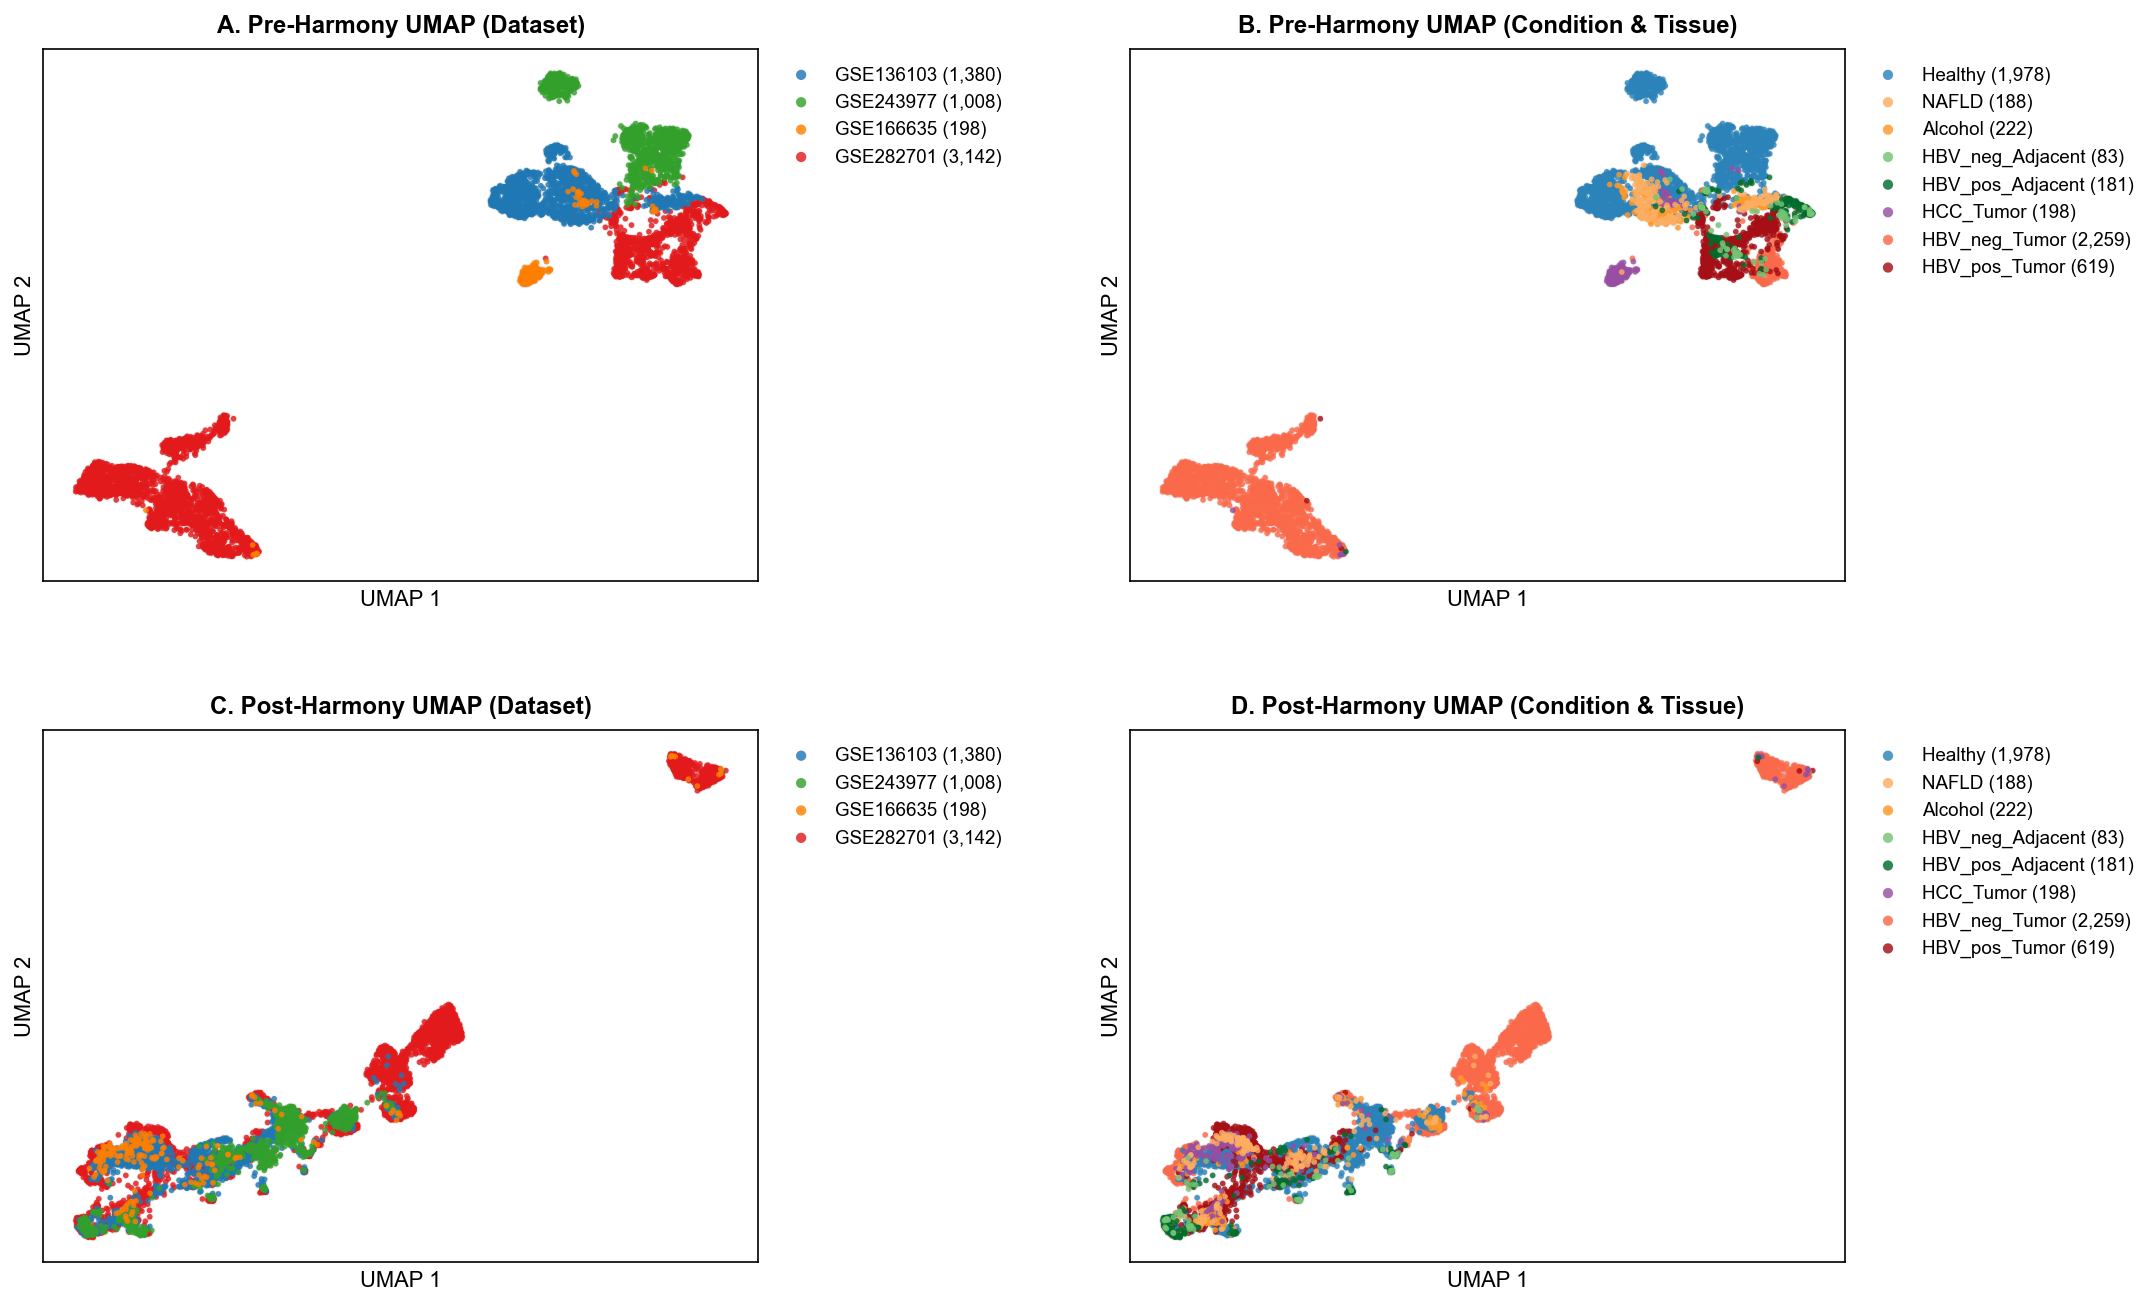

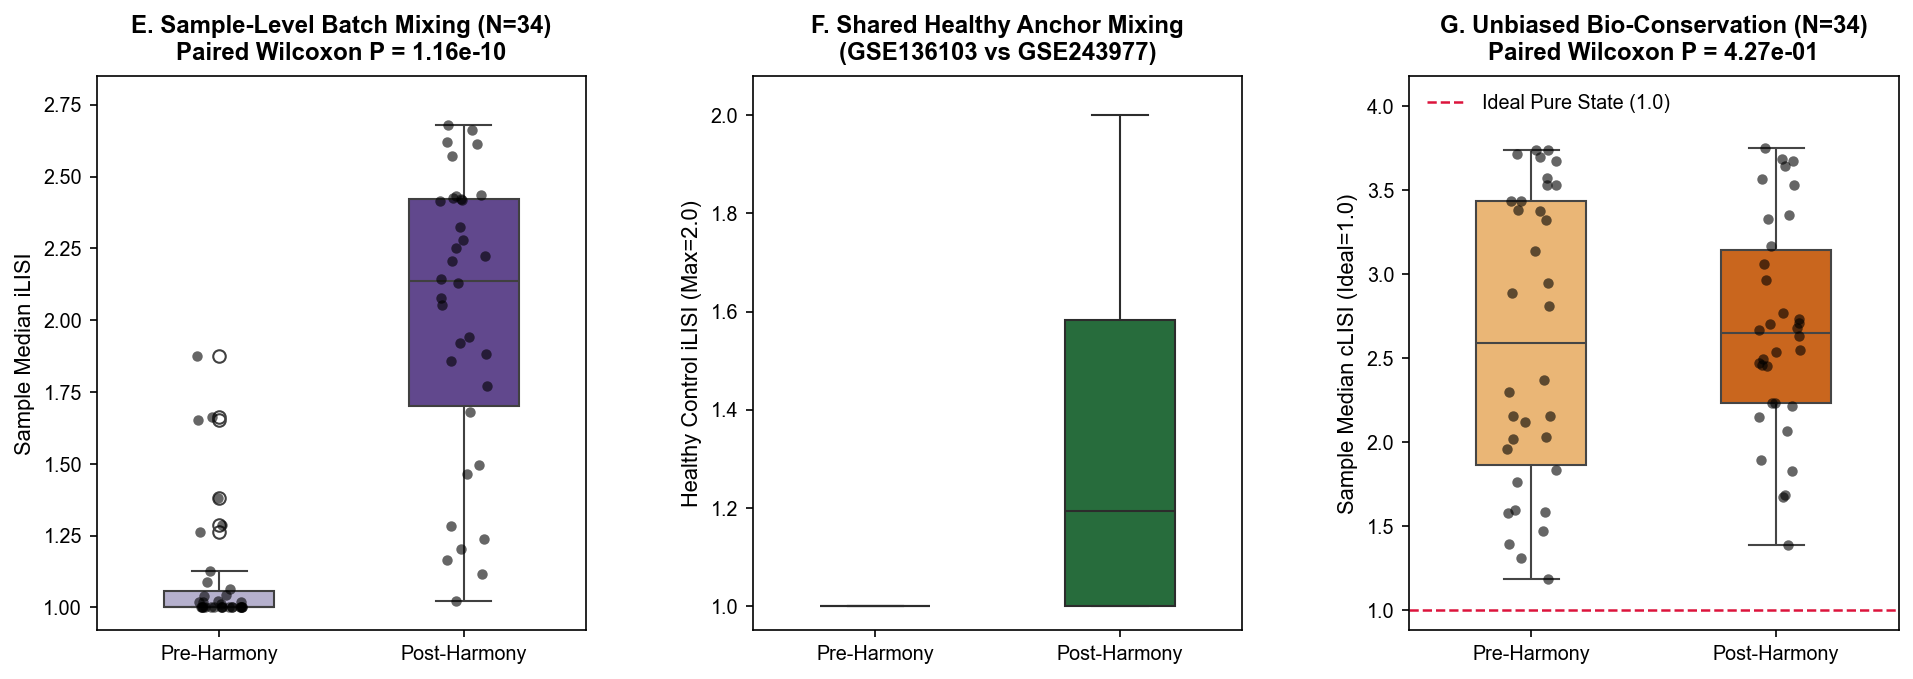

In [ ]:
def plot_bmj_umap(ax, coords, series, palette, title):
    ax.scatter(coords[:, 0], coords[:, 1], c="#e5e5e5", s=14, alpha=0.45, edgecolors="none", rasterized=True)
    val_counts = series.value_counts()
    for cat in val_counts.index:
        mask = (series == cat).values
        ax.scatter(
            coords[mask, 0], coords[mask, 1],
            c=palette.get(cat, "#333333"), label=f"{cat} ({mask.sum():,})",
            s=7.5, alpha=0.82, edgecolors="none", rasterized=True
        )
    ax.set_title(title, fontweight="bold", fontsize=11.5, pad=8)
    ax.set_xlabel("UMAP 1")
    ax.set_ylabel("UMAP 2")
    ax.set_xticks([])
    ax.set_yticks([])
    handles, labels = ax.get_legend_handles_labels()
    cat_order = [k for k in palette.keys() if k in val_counts.index]
    h_map = {l.split(" (")[0]: (h, l) for h, l in zip(handles, labels)}
    ax.legend(
        [h_map[k][0] for k in cat_order], [h_map[k][1] for k in cat_order],
        bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False, fontsize=9, markerscale=1.8
    )

fig, axes = plt.subplots(2, 2, figsize=(15.5, 10.5))
plt.subplots_adjust(wspace=0.52, hspace=0.28)
plot_bmj_umap(axes[0, 0], adata.obsm["X_umap_pre"],     adata.obs["dataset_id"],      PALETTE_DS,   "A. Pre-Harmony UMAP (Dataset)")
plot_bmj_umap(axes[0, 1], adata.obsm["X_umap_pre"],     adata.obs["condition_group"], PALETTE_COND, "B. Pre-Harmony UMAP (Condition & Tissue)")
plot_bmj_umap(axes[1, 0], adata.obsm["X_umap_harmony"], adata.obs["dataset_id"],      PALETTE_DS,   "C. Post-Harmony UMAP (Dataset)")
plot_bmj_umap(axes[1, 1], adata.obsm["X_umap_harmony"], adata.obs["condition_group"], PALETTE_COND, "D. Post-Harmony UMAP (Condition & Tissue)")
save_pub_fig("Fig2A_D_Integration_UMAP_Comparison.png")

fig_e, axes_e = plt.subplots(1, 3, figsize=(15.5, 4.8))
plt.subplots_adjust(wspace=0.34)

df_s_ilisi = pd.DataFrame({
    "Stage": ["Pre-Harmony"] * len(sample_lisi) + ["Post-Harmony"] * len(sample_lisi),
    "iLISI": np.concatenate([sample_lisi["iLISI_Pre"], sample_lisi["iLISI_Post"]]),
})
sns.boxplot(data=df_s_ilisi, x="Stage", y="iLISI", palette=["#b2abd2", "#5e3c99"], width=0.45, ax=axes_e[0])
sns.stripplot(data=df_s_ilisi, x="Stage", y="iLISI", color="black", size=5, alpha=0.6, ax=axes_e[0])
axes_e[0].set_title(f"E. Sample-Level Batch Mixing (N={len(sample_lisi)})\nPaired Wilcoxon P = {p_sample_ilisi:.2e}", fontweight="bold", pad=8)
axes_e[0].set_ylabel("Sample Median iLISI")
axes_e[0].set_xlabel("")
axes_e[0].set_ylim(0.92, 2.85)

df_h_ilisi = pd.DataFrame({
    "Stage": ["Pre-Harmony"] * len(ilisi_healthy_pre) + ["Post-Harmony"] * len(ilisi_healthy_post),
    "iLISI": np.concatenate([ilisi_healthy_pre, ilisi_healthy_post]),
})
sns.boxplot(data=df_h_ilisi, x="Stage", y="iLISI", palette=["#a6dba0", "#1b7837"], width=0.45, showfliers=False, ax=axes_e[1])
axes_e[1].set_title("F. Shared Healthy Anchor Mixing\n(GSE136103 vs GSE243977)", fontweight="bold", pad=8)
axes_e[1].set_ylabel("Healthy Control iLISI (Max=2.0)")
axes_e[1].set_xlabel("")
axes_e[1].set_ylim(0.95, 2.08)

df_s_clisi = pd.DataFrame({
    "Stage": ["Pre-Harmony"] * len(sample_lisi) + ["Post-Harmony"] * len(sample_lisi),
    "cLISI": np.concatenate([sample_lisi["cLISI_Pre"], sample_lisi["cLISI_Post"]]),
})
sns.boxplot(data=df_s_clisi, x="Stage", y="cLISI", palette=["#fdb863", "#e66101"], width=0.45, ax=axes_e[2])
sns.stripplot(data=df_s_clisi, x="Stage", y="cLISI", color="black", size=5, alpha=0.6, ax=axes_e[2])
axes_e[2].axhline(1.0, color="crimson", linestyle="--", linewidth=1.2, label="Ideal Pure State (1.0)")
axes_e[2].set_title(f"G. Unbiased Bio-Conservation (N={len(sample_lisi)})\nPaired Wilcoxon P = {p_sample_clisi:.2e}", fontweight="bold", pad=8)
axes_e[2].set_ylabel("Sample Median cLISI (Ideal=1.0)")
axes_e[2].set_xlabel("")
axes_e[2].set_ylim(0.88, 4.18)
axes_e[2].legend(frameon=False, loc="upper left", fontsize=9.5)

## 6. Conserved Four-State HSC Architecture & Marker Specificity (Figure 3)

[CONCORDANCE AUDIT] Pre- vs Post-Harmony State Agreement: 92.91% | Cohen's Kappa = 0.904 | ARI = 0.822

=== MARKER-BLIND GEOMETRIC VALIDATION (DONOR-GROUPED 5-FOLD CV & LODO) ===


,Validation_Scheme,Test_Cohort,N_Test_Cells,Accuracy,Cohens_Kappa,Weighted_F1,Macro_F1
0,5-Fold Donor-Grouped Cross-Validation (No Same...,All Cohorts (28 Donors),5728,0.528,0.375,0.522,0.526
1,Leave-One-Dataset-Out (LODO) Transfer,GSE136103,1380,0.608,0.476,0.619,0.595
2,Leave-One-Dataset-Out (LODO) Transfer,GSE243977,1008,0.387,0.191,0.389,0.389
3,Leave-One-Dataset-Out (LODO) Transfer,GSE166635,198,0.571,0.423,0.563,0.563
4,Leave-One-Dataset-Out (LODO) Transfer,GSE282701,3142,0.513,0.362,0.513,0.511



=== GATING SENSITIVITY AUDIT (Primary vs. Stringent Tier Pearson r = 0.8829, P = 1.1705e-01) ===


,HSC_State,"Primary_Clean_HSCs (n=5,728) (%)","Stringent_HSCs (n=4,055, Z_VSMC<0.5 & Z_PF<0.5) (%)",Absolute_Diff (%)
0,qHSC,20.16,19.63,-0.53
1,A1,24.23,17.66,-6.57
2,A2,33.59,38.15,4.56
3,INF,22.01,24.56,2.55


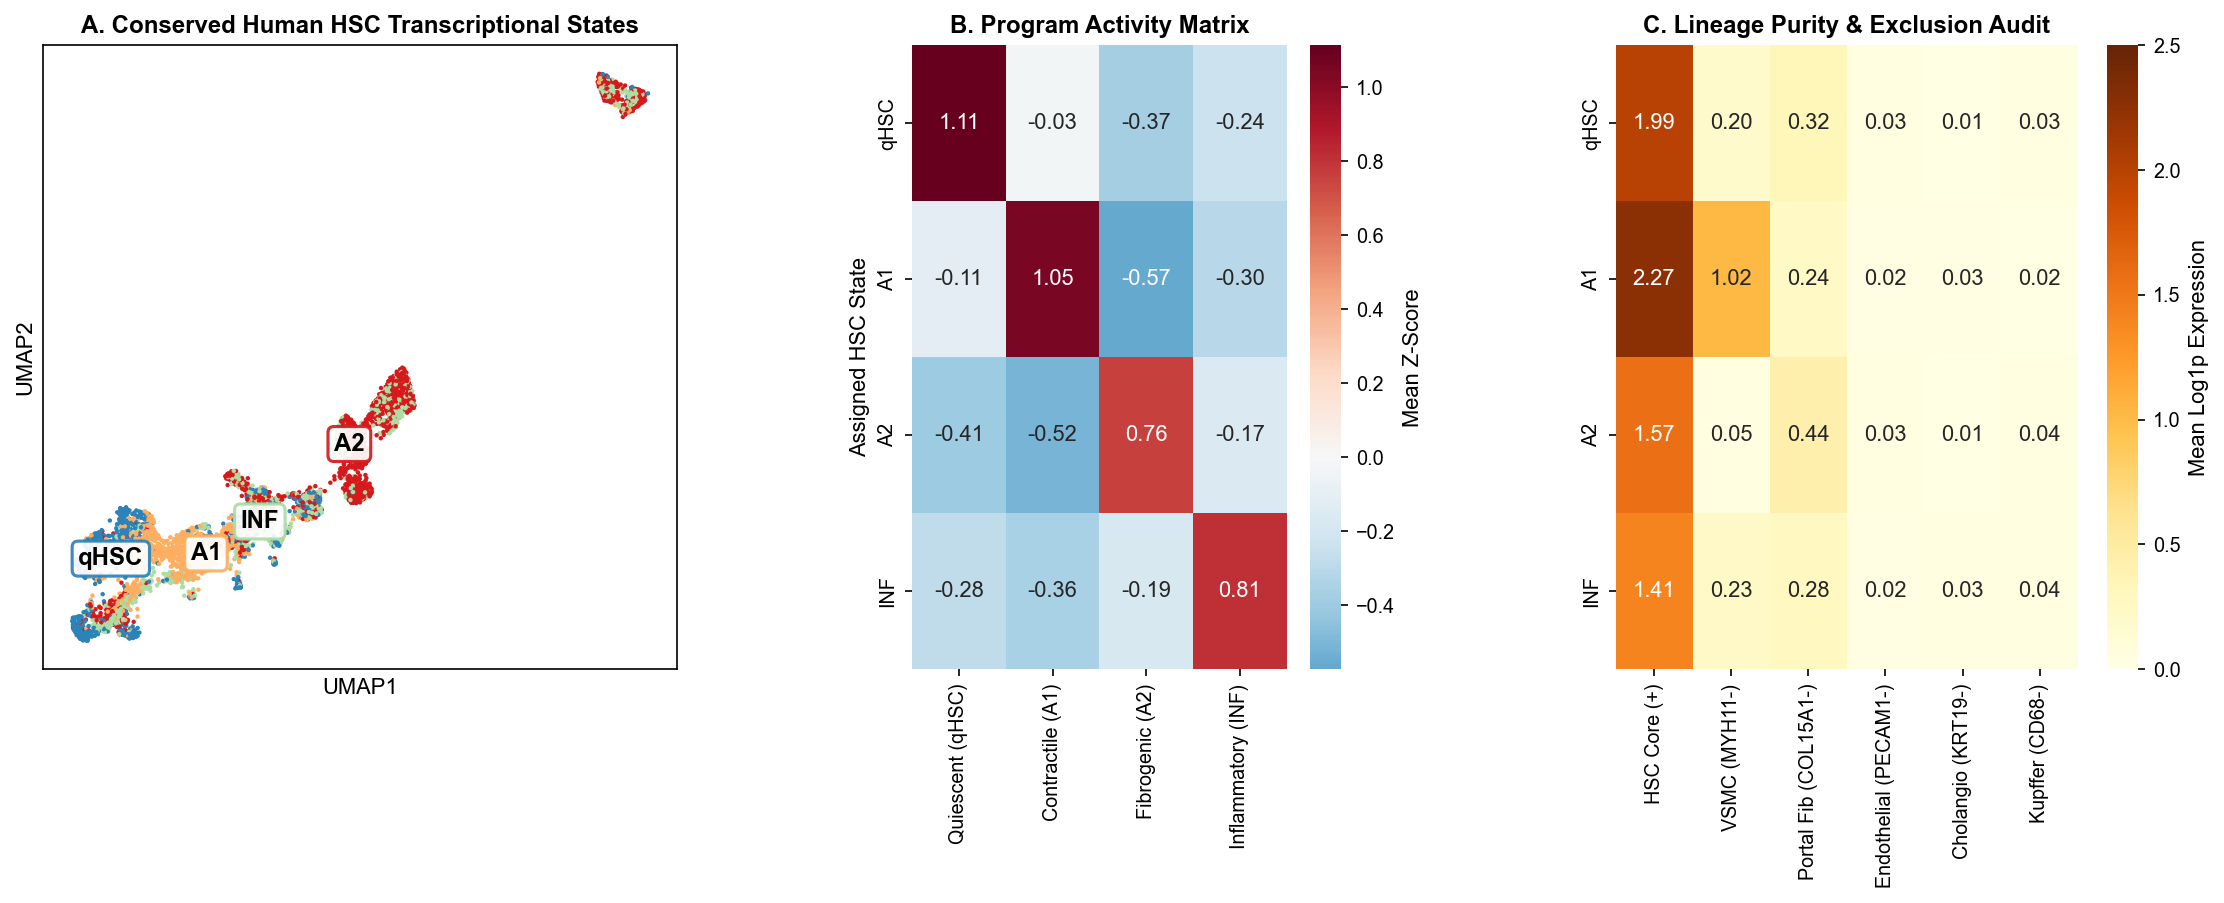

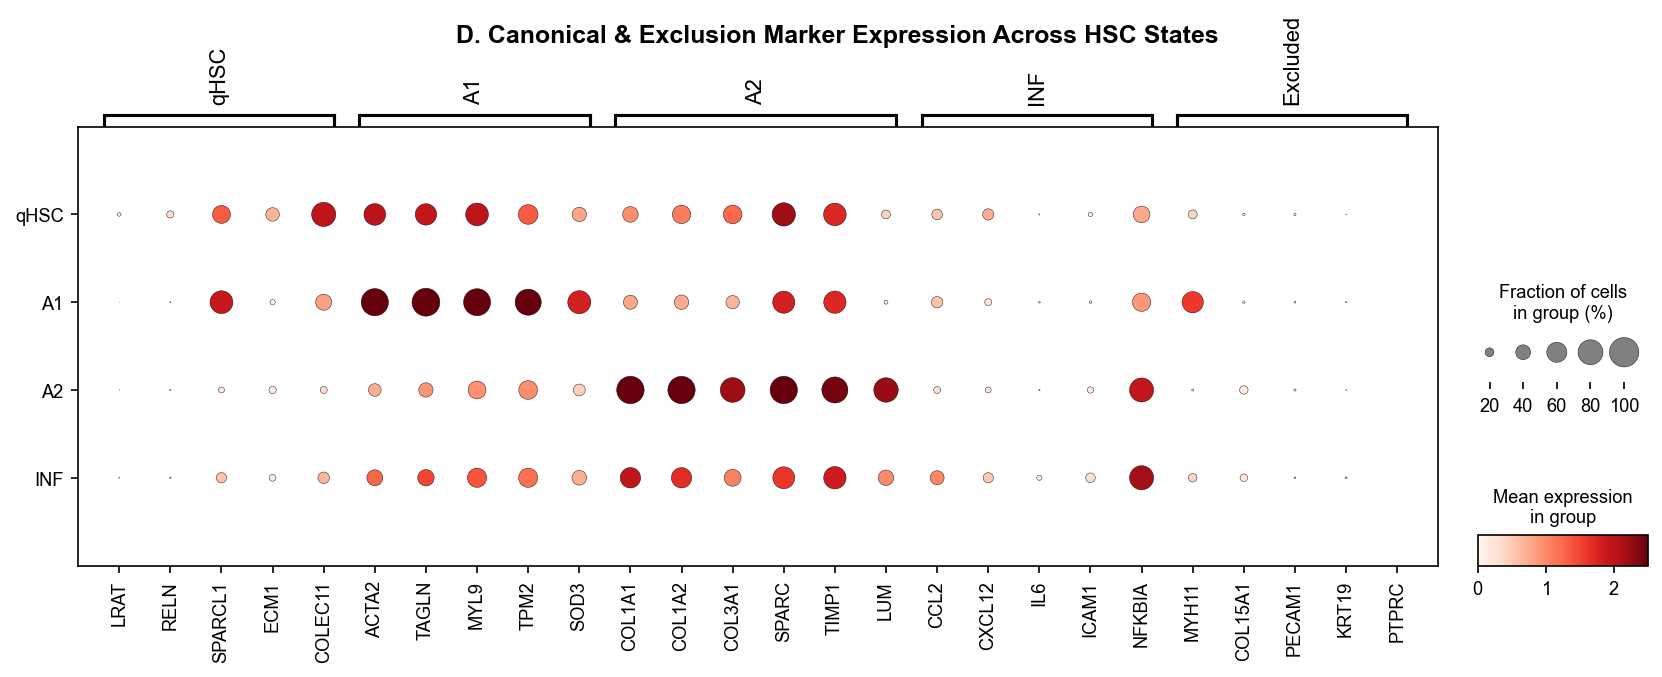

In [ ]:
raw_score_cols = [f"RawScore_{s}" for s in ["qHSC", "A1", "A2", "INF"]]
Z_mat = np.zeros((adata.n_obs, 4), dtype=np.float32)
for ds_id in adata.obs["dataset_id"].unique():
    m_ds = (adata.obs["dataset_id"] == ds_id).values
    Z_mat[m_ds, :] = StandardScaler().fit_transform(adata.obs.loc[m_ds, raw_score_cols].values)

# kNN Graph on Harmony
conn = adata.obsp["connectivities"].tocsr()
row_sums = np.asarray(conn.sum(axis=1)).ravel()
row_sums[row_sums == 0] = 1.0
D_inv = sp.diags(1.0 / row_sums)
Z_smooth = 0.70 * Z_mat + 0.30 * (D_inv @ conn @ Z_mat)

for idx, st in enumerate(["qHSC", "A1", "A2", "INF"]):
    adata.obs[f"Z_{st}"] = Z_smooth[:, idx]

adata.obs["HSC_state"] = pd.Categorical(
    pd.DataFrame(Z_smooth, index=adata.obs_names, columns=["qHSC", "A1", "A2", "INF"]).idxmax(axis=1).values,
    categories=["qHSC", "A1", "A2", "INF"], ordered=True,
)
adata.uns["HSC_state_colors"] = [PALETTE_STATE[k] for k in ["qHSC", "A1", "A2", "INF"]]

# Pre- vs Post-Harmony Label Concordance Audit
pre_state, post_state = adata.obs["pre_state_indep"].astype(str), adata.obs["HSC_state"].astype(str)
acc_pre_post   = accuracy_score(pre_state, post_state) * 100
kappa_pre_post = cohen_kappa_score(pre_state, post_state)
ari_pre_post   = adjusted_rand_score(pre_state, post_state)
print(f"[CONCORDANCE AUDIT] Pre- vs Post-Harmony State Agreement: {acc_pre_post:.2f}% | Cohen's Kappa = {kappa_pre_post:.3f} | ARI = {ari_pre_post:.3f}")

# Donor-Grouped 5-Fold Cross-Validation & LODO Transfer 
X_geom = np.zeros_like(adata.obsm["X_harmony"])
for ds_id in adata.obs["dataset_id"].unique():
    m_ds = (adata.obs["dataset_id"] == ds_id).values
    X_geom[m_ds, :] = StandardScaler().fit_transform(adata.obsm["X_harmony"][m_ds, :])

y_true = adata.obs["HSC_state"].astype(str).values
donor_groups = adata.obs["global_patient_id"].astype(str).values

rf_cv = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=4)
sgkf = StratifiedGroupKFold(n_splits=5)
y_pred_cv = cross_val_predict(rf_cv, X_geom, y_true, groups=donor_groups, cv=sgkf, n_jobs=4)

lodo_rows = [{
    "Validation_Scheme": "5-Fold Donor-Grouped Cross-Validation (No Same-Donor Leakage)",
    "Test_Cohort": "All Cohorts (28 Donors)",
    "N_Test_Cells": len(y_true),
    "Accuracy": round(accuracy_score(y_true, y_pred_cv), 3),
    "Cohens_Kappa": round(cohen_kappa_score(y_true, y_pred_cv), 3),
    "Weighted_F1": round(f1_score(y_true, y_pred_cv, average="weighted"), 3),
    "Macro_F1": round(f1_score(y_true, y_pred_cv, average="macro"), 3),
}]

for holdout_ds in adata.obs["dataset_id"].unique():
    test_mask = (adata.obs["dataset_id"] == holdout_ds).values
    train_mask = ~test_mask
    rf_lodo = RandomForestClassifier(n_estimators=300, max_depth=12, class_weight="balanced", random_state=RANDOM_STATE, n_jobs=4)
    rf_lodo.fit(X_geom[train_mask], y_true[train_mask])
    y_pred_lodo = rf_lodo.predict(X_geom[test_mask])
    lodo_rows.append({
        "Validation_Scheme": "Leave-One-Dataset-Out (LODO) Transfer",
        "Test_Cohort": holdout_ds,
        "N_Test_Cells": int(test_mask.sum()),
        "Accuracy": round(accuracy_score(y_true[test_mask], y_pred_lodo), 3),
        "Cohens_Kappa": round(cohen_kappa_score(y_true[test_mask], y_pred_lodo), 3),
        "Weighted_F1": round(f1_score(y_true[test_mask], y_pred_lodo, average="weighted"), 3),
        "Macro_F1": round(f1_score(y_true[test_mask], y_pred_lodo, average="macro"), 3),
    })

df_ml_val = pd.DataFrame(lodo_rows)
df_ml_val.to_csv(os.path.join(TAB_DIR, "Table2B_State_Geometric_ML_and_LODO_Validation.csv"), index=False)
print("\n=== MARKER-BLIND GEOMETRIC VALIDATION (DONOR-GROUPED 5-FOLD CV & LODO) ===")
display(df_ml_val)

# Sensitivity Analysis 
z_vsmc_audit = StandardScaler().fit_transform(adata.obs[["Audit_VSMC_Excluded"]]).ravel()
z_pf_audit   = StandardScaler().fit_transform(adata.obs[["Audit_PortalFib_Excluded"]]).ravel()
stringent_mask = (z_vsmc_audit < 0.5) & (z_pf_audit < 0.5)
if "is_HSC_stringent" in adata.obs.columns:
    stringent_mask = adata.obs["is_HSC_stringent"].astype(bool).values

prop_primary   = adata.obs["HSC_state"].value_counts(normalize=True).loc[["qHSC", "A1", "A2", "INF"]] * 100
prop_stringent = adata.obs.loc[stringent_mask, "HSC_state"].value_counts(normalize=True).loc[["qHSC", "A1", "A2", "INF"]] * 100
r_sens, p_sens = pearsonr(prop_primary.values, prop_stringent.values)

df_sens = pd.DataFrame({
    "HSC_State": ["qHSC", "A1", "A2", "INF"],
    f"Primary_Clean_HSCs (n={adata.n_obs:,}) (%)": prop_primary.values.round(2),
    f"Stringent_HSCs (n={int(stringent_mask.sum()):,}, Z_VSMC<0.5 & Z_PF<0.5) (%)": prop_stringent.values.round(2),
    "Absolute_Diff (%)": (prop_stringent.values - prop_primary.values).round(2),
})
df_sens.to_csv(os.path.join(TAB_DIR, "Table2C_Marker_Gating_Sensitivity_Audit.csv"), index=False)
print(f"\n=== GATING SENSITIVITY AUDIT (Primary vs. Stringent Tier Pearson r = {r_sens:.4f}, P = {p_sens:.4e}) ===")
display(df_sens)

# UMAP, Program Activity Matrix & Log1p Lineage Purity Audit
fig, axes = plt.subplots(1, 3, figsize=(18.5, 5.4), gridspec_kw={"width_ratios": [1.15, 0.85, 1.05]})
plt.subplots_adjust(wspace=0.42)

sc.pl.umap(
    adata, color="HSC_state", palette=PALETTE_STATE, ax=axes[0],
    show=False, frameon=True, legend_loc="none",
    title="A. Conserved Human HSC Transcriptional States", size=18
)
axes[0].set_title("A. Conserved Human HSC Transcriptional States", fontweight="bold", fontsize=11.5)
umap_coords = adata.obsm["X_umap"]
label_offsets = {"qHSC": (-1.2, -0.9), "A1": (1.6, -0.3), "A2": (-0.6, 0.5), "INF": (-0.7, -0.9)}
for st in ["qHSC", "A1", "A2", "INF"]:
    st_mask = (adata.obs["HSC_state"] == st).values
    if st_mask.sum() > 0:
        cx, cy = np.median(umap_coords[st_mask, 0]), np.median(umap_coords[st_mask, 1])
        dx, dy = label_offsets[st]
        axes[0].text(
            cx + dx, cy + dy, st, fontsize=11.5, fontweight="bold", ha="center", va="center",
            bbox=dict(boxstyle="round,pad=0.25", fc="white", ec=PALETTE_STATE[st], lw=1.5, alpha=0.92)
        )

state_z_means = adata.obs.groupby("HSC_state", observed=True)[["Z_qHSC", "Z_A1", "Z_A2", "Z_INF"]].mean()
state_z_means.columns = ["Quiescent (qHSC)", "Contractile (A1)", "Fibrogenic (A2)", "Inflammatory (INF)"]
sns.heatmap(state_z_means, annot=True, fmt=".2f", cmap="RdBu_r", center=0, cbar_kws={"label": "Mean Z-Score"}, ax=axes[1])
axes[1].set_title("B. Program Activity Matrix", fontweight="bold")
axes[1].set_ylabel("Assigned HSC State")

lineage_check_genes = {
    "HSC Core (+)":          ["DCN", "IGFBP7", "COL1A2", "SPARCL1", "ACTA2"],
    "VSMC (MYH11-)":         ["MYH11", "ACTG2", "CNN1"],
    "Portal Fib (COL15A1-)": ["COL15A1", "ELN", "THY1"],
    "Endothelial (PECAM1-)": ["PECAM1", "VWF", "CDH5"],
    "Cholangio (KRT19-)":    ["KRT19", "EPCAM", "KRT7"],
    "Kupffer (CD68-)":       ["CD68", "CD163", "MARCO", "PTPRC"],
}
X_raw_log = adata.raw.X.tocsr() if sp.issparse(adata.raw.X) else sp.csr_matrix(adata.raw.X)
raw_var_list = list(adata.raw.var_names)

purity_df = pd.DataFrame(index=adata.obs_names)
for lin_name, g_list in lineage_check_genes.items():
    g_idx = [raw_var_list.index(g) for g in g_list if g in raw_var_list]
    purity_df[lin_name] = np.asarray(X_raw_log[:, g_idx].mean(axis=1)).ravel() if len(g_idx) > 0 else 0.0

purity_df["HSC_state"] = adata.obs["HSC_state"].values
purity_means = purity_df.groupby("HSC_state", observed=True).mean()

sns.heatmap(purity_means, annot=True, fmt=".2f", cmap="YlOrBr", vmin=0.0, vmax=2.5, cbar_kws={"label": "Mean Log1p Expression"}, ax=axes[2])
axes[2].set_title("C. Lineage Purity & Exclusion Audit", fontweight="bold")
axes[2].set_ylabel("")
save_pub_fig("Fig3A_C_HSC_States_and_Purity_Audit.png")

# Canonical & Exclusion Marker Dotplot
marker_dict_clean = {
    "qHSC":     [g for g in ["LRAT", "RELN", "SPARCL1", "ECM1", "COLEC11"] if g in adata.raw.var_names],
    "A1":       [g for g in ["ACTA2", "TAGLN", "MYL9", "TPM2", "SOD3"] if g in adata.raw.var_names],
    "A2":       [g for g in ["COL1A1", "COL1A2", "COL3A1", "SPARC", "TIMP1", "LUM"] if g in adata.raw.var_names],
    "INF":      [g for g in ["CCL2", "CXCL12", "IL6", "ICAM1", "NFKBIA"] if g in adata.raw.var_names],
    "Excluded": [g for g in ["MYH11", "COL15A1", "PECAM1", "KRT19", "PTPRC"] if g in adata.raw.var_names],
}
sc.pl.dotplot(
    adata, var_names=marker_dict_clean, groupby="HSC_state",
    use_raw=True, standard_scale=None, vmax=2.5, cmap="Reds",
    figsize=(13.5, 3.8), show=False,
)
plt.suptitle("D. Canonical & Exclusion Marker Expression Across HSC States", fontweight="bold", y=1.06, fontsize=12)
plt.savefig(os.path.join(FIG_DIR, "Fig3D_Canonical_and_Exclusion_Dotplot.png"), dpi=300, bbox_inches="tight", pad_inches=0.15)
plt.savefig(os.path.join(FIG_DIR, "Fig3D_Canonical_and_Exclusion_Dotplot.pdf"), bbox_inches="tight", pad_inches=0.15)
plt.show()

## 7. Marker-Blind Cross-Validation & LODO Generalization

In [ ]:
bio_meta = (
    adata.obs[["sample_bio_id", "global_patient_id", "dataset_id", "tissue_context", "etiology", "condition_group"]]
    .drop_duplicates(subset=["sample_bio_id"])
    .set_index("sample_bio_id")
)

state_counts = pd.crosstab(adata.obs["sample_bio_id"], adata.obs["HSC_state"])
state_props  = state_counts.div(state_counts.sum(axis=1), axis=0) * 100.0
bio_scores   = adata.obs.groupby("sample_bio_id", observed=True)[["Z_qHSC", "Z_A1", "Z_A2", "Z_INF"]].mean()

df_bio_summary = bio_meta.join(state_props).join(bio_scores)
df_bio_summary["total_HSCs"] = state_counts.sum(axis=1)
df_bio_summary.to_csv(os.path.join(TAB_DIR, "Table3_Sample_Level_HSC_Composition_N34_Verified.csv"))
print(f"[VERIFIED] Table 3 exported for {len(df_bio_summary)} biological samples (28 unique patients).")

# Paired GSE282701 subsets (n = 6 matched pairs) & Leave-P15-Out subset (N = 32 samples)
df_282_paired = df_bio_summary[df_bio_summary["dataset_id"] == "GSE282701"].copy()
adj_paired = df_282_paired[df_282_paired["tissue_context"] == "Adjacent_Liver"].sort_values("global_patient_id")
tum_paired = df_282_paired[df_282_paired["tissue_context"] == "Tumor_Core"].sort_values("global_patient_id")
df_no_p15  = df_bio_summary[df_bio_summary["global_patient_id"] != "GSE282701_P15"].copy()

kw_records = []
for st in ["qHSC", "A1", "A2", "INF"]:
    groups_cond = [grp[st].values for _, grp in df_bio_summary.groupby("condition_group") if len(grp) >= 2]
    stat_c, p_c = kruskal(*groups_cond)

    groups_tiss = [grp[st].values for _, grp in df_bio_summary.groupby("tissue_context") if len(grp) >= 2]
    stat_t, p_t = kruskal(*groups_tiss)

    tum_vals    = df_bio_summary.loc[df_bio_summary["tissue_context"] == "Tumor_Core", st].values
    nontum_vals = df_bio_summary.loc[df_bio_summary["tissue_context"] != "Tumor_Core", st].values
    p_tum_vs_non = mannwhitneyu(tum_vals, nontum_vals).pvalue

    # Leave-P15-Out Sensitivity Mann-Whitney Test
    tum_no_p15    = df_no_p15.loc[df_no_p15["tissue_context"] == "Tumor_Core", st].values
    nontum_no_p15 = df_no_p15.loc[df_no_p15["tissue_context"] != "Tumor_Core", st].values
    p_no_p15 = mannwhitneyu(tum_no_p15, nontum_no_p15).pvalue

    # Paired Wilcoxon signed-rank test on the 6 matched HCC patients in GSE282701
    diff_pair = tum_paired[st].values - adj_paired[st].values
    _, p_paired_282 = wilcoxon(tum_paired[st].values, adj_paired[st].values, zero_method="zsplit")
    n_up_pair = int((diff_pair > 0).sum())
    n_dn_pair = int((diff_pair < 0).sum())

    kw_records.append({
        "HSC_State": st,
        "KW_Stat_Condition": round(stat_c, 3),
        "P_Condition": p_c,
        "KW_Stat_TissueContext": round(stat_t, 3),
        "P_TissueContext": p_t,
        "P_Tumor_vs_NonTumor (All N=34)": p_tum_vs_non,
        "P_Tumor_vs_NonTumor (Leave-P15-Out N=32)": p_no_p15,
        "Paired_GSE282701_Direction (Up/Down in Tumor, n=6)": f"{n_up_pair} Up / {n_dn_pair} Down",
        "Paired_GSE282701_Wilcoxon_P": p_paired_282,
    })

df_kw = pd.DataFrame(kw_records)
df_kw["FDR_Condition"]                   = multipletests(df_kw["P_Condition"], method="fdr_bh")[1]
df_kw["FDR_TissueContext"]               = multipletests(df_kw["P_TissueContext"], method="fdr_bh")[1]
df_kw["FDR_Tumor_vs_NonTum (All N=34)"]  = multipletests(df_kw["P_Tumor_vs_NonTumor (All N=34)"], method="fdr_bh")[1]
df_kw["FDR_Leave_P15_Out (N=32)"]        = multipletests(df_kw["P_Tumor_vs_NonTumor (Leave-P15-Out N=32)"], method="fdr_bh")[1]
df_kw["FDR_Paired_GSE282701 (n=6)"]      = multipletests(df_kw["Paired_GSE282701_Wilcoxon_P"], method="fdr_bh")[1]
df_kw.to_csv(os.path.join(TAB_DIR, "Table3B_Composition_Statistical_Tests.csv"), index=False)
display(df_kw)

## 8. Sample-Level State Composition Analysis (Figure 4)

[VERIFIED] Table 3 exported for 34 biological samples (28 unique patients).


,HSC_State,KW_Stat_Condition,P_Condition,KW_Stat_TissueContext,P_TissueContext,P_Tumor_vs_NonTumor (All N=34),P_Tumor_vs_NonTumor (Leave-P15-Out N=32),"Paired_GSE282701_Direction (Up/Down in Tumor, n=6)",Paired_GSE282701_Wilcoxon_P,FDR_Condition,FDR_TissueContext,FDR_Tumor_vs_NonTum (All N=34),FDR_Leave_P15_Out (N=32),FDR_Paired_GSE282701 (n=6)
0,qHSC,14.762,0.022195,12.109,0.002347,0.339997,0.715330,2 Up / 4 Down,0.15625,0.044390,0.004695,0.787692,0.71533,0.3125
1,A1,9.223,0.161425,0.497,0.779828,0.611696,0.315754,3 Up / 3 Down,0.68750,0.185851,0.779828,0.815595,0.61996,0.6875
2,A2,17.120,0.008851,13.924,0.000947,1.000000,0.464970,5 Up / 0 Down,0.06250,0.035402,0.003789,1.000000,0.61996,0.2500
3,INF,8.788,0.185851,4.702,0.095276,0.393846,0.327012,4 Up / 2 Down,0.56250,0.185851,0.127034,0.787692,0.61996,0.6875


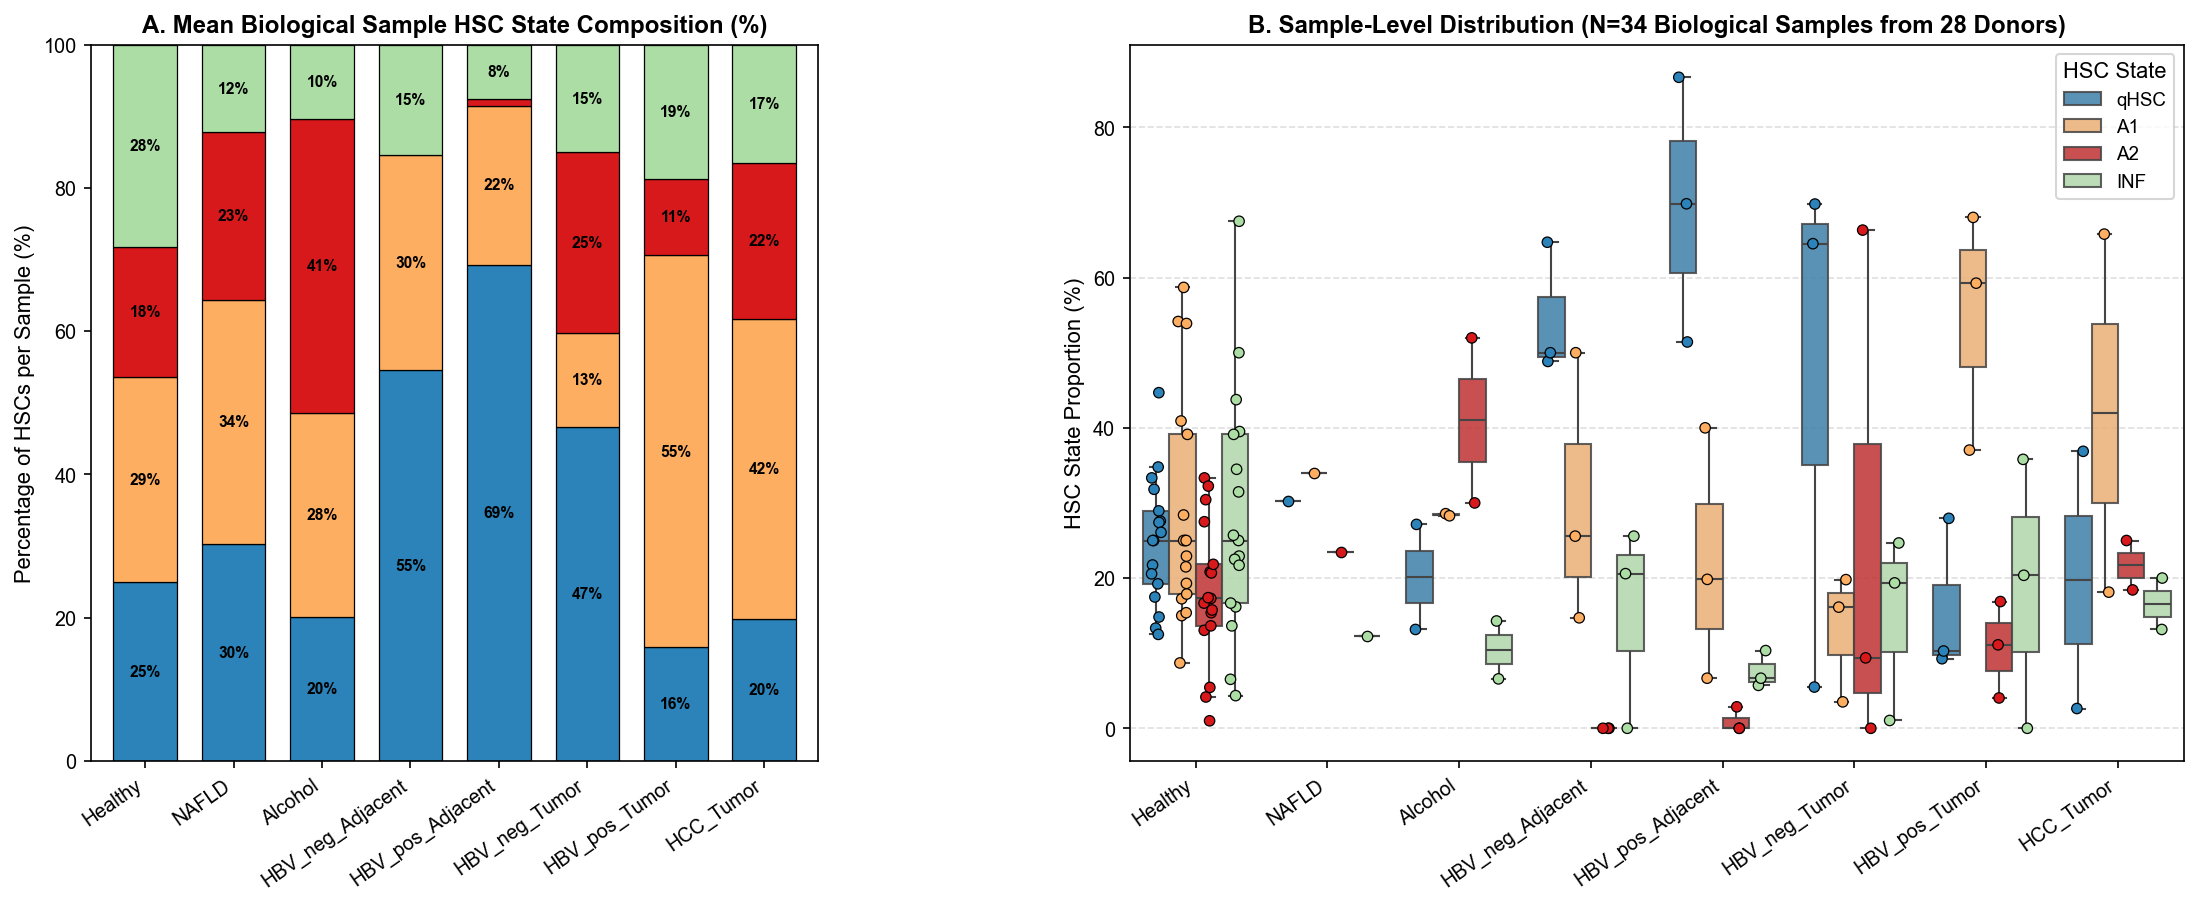

In [ ]:
order_cond = [
    c for c in ["Healthy", "NAFLD", "Alcohol", "HBV_neg_Adjacent", "HBV_pos_Adjacent", "HBV_neg_Tumor", "HBV_pos_Tumor", "HCC_Tumor"]
    if c in df_bio_summary["condition_group"].unique()
]

fig, axes = plt.subplots(1, 2, figsize=(18.0, 6.2), gridspec_kw={"width_ratios": [1.0, 1.45]})
plt.subplots_adjust(wspace=0.35)

mean_props = df_bio_summary.groupby("condition_group", observed=True)[["qHSC", "A1", "A2", "INF"]].mean().loc[order_cond]
mean_props.plot(
    kind="bar", stacked=True, color=[PALETTE_STATE[k] for k in ["qHSC", "A1", "A2", "INF"]],
    width=0.72, edgecolor="black", linewidth=0.6, ax=axes[0], legend=False
)
bottom = np.zeros(len(mean_props))
for st in ["qHSC", "A1", "A2", "INF"]:
    vals = mean_props[st].values
    for i, v in enumerate(vals):
        if v >= 4:
            axes[0].text(i, bottom[i] + v/2, f"{v:.0f}%", ha="center", va="center", fontsize=7.5, fontweight="bold")
    bottom += vals
axes[0].set_title("A. Mean Biological Sample HSC State Composition (%)", fontweight="bold")
axes[0].set_ylabel("Percentage of HSCs per Sample (%)")
axes[0].set_xlabel("")
axes[0].set_xticklabels(order_cond, rotation=35, ha="right")
axes[0].set_ylim(0, 100)

df_melt = df_bio_summary.reset_index().melt(
    id_vars=["sample_bio_id", "condition_group"],
    value_vars=["qHSC", "A1", "A2", "INF"],
    var_name="HSC_State", value_name="Proportion_Pct",
)
sns.boxplot(
    data=df_melt, x="condition_group", y="Proportion_Pct", hue="HSC_State",
    order=order_cond, palette=PALETTE_STATE, showfliers=False, boxprops=dict(alpha=0.85), ax=axes[1],
)
sns.stripplot(
    data=df_melt, x="condition_group", y="Proportion_Pct", hue="HSC_State",
    order=order_cond, palette=PALETTE_STATE, dodge=True, jitter=0.15,
    size=5, edgecolor="black", linewidth=0.6, legend=False, ax=axes[1],
)
axes[1].set_title(f"B. Sample-Level Distribution (N={len(df_bio_summary)} Biological Samples from {N_PAT_TOTAL} Donors)", fontweight="bold")
axes[1].set_ylabel("HSC State Proportion (%)")
axes[1].set_xlabel("")
axes[1].set_xticklabels(order_cond, rotation=35, ha="right")
axes[1].legend(title="HSC State", loc="upper right", frameon=True)
axes[1].grid(axis="y", linestyle="--", alpha=0.4)

## 9. Pseudobulk Differential Expression (PyDESeq2) & Hallmark GSEA (Figure 5), Bootstrap Undirected PAGA Connectivity (Figure 6)

[VERIFIED] Pseudobulk Matrix: 34 Biological Samples × 10,574 Clean Genes.
Using None as control genes, passed at DeseqDataSet initialization


Fitting size factors...
... done in 0.00 seconds.

Fitting dispersions...
... done in 0.69 seconds.

Fitting dispersion trend curve...
... done in 0.09 seconds.

Fitting MAP dispersions...
... done in 0.91 seconds.

Fitting LFCs...
... done in 0.49 seconds.

Calculating cook's distance...
... done in 0.00 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.19 seconds.



Log2 fold change & Wald test p-value: condition_group Alcohol vs Healthy
              baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
FAM41C        4.665139       -2.341368  1.417524 -1.651730  0.098590       NaN
SAMD11       11.765071        3.193224  0.929824  3.434225  0.000594  0.024854
NOC2L        22.720029        0.099535  0.625462  0.159139  0.873559  0.989295
HES4        235.255226       -0.263818  0.422762 -0.624033  0.532606  0.943791
ISG15       137.454808        1.293962  0.429070  3.015739  0.002564  0.072337
...                ...             ...       ...       ...       ...       ...
S100B         4.145162       -2.914581  3.141730 -0.927699  0.353564       NaN
PRMT2        67.934795       -0.289609  0.435456 -0.665071  0.506005  0.938855
AL592183.1   12.368852       -0.140752  0.739057 -0.190448  0.848958  0.987554
AC007325.4    7.590984       -0.158262  0.906464 -0.174593  0.861399  0.988625
AC240274.1    2.435217       -3.928634  2.669658 -1.471587

Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 0.85 seconds.

Fitting dispersion trend curve...
... done in 0.09 seconds.

Fitting MAP dispersions...
... done in 1.00 seconds.

Fitting LFCs...
... done in 1.00 seconds.

Calculating cook's distance...
... done in 0.00 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.35 seconds.



... (13 outputs left out)

Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 0.78 seconds.

Fitting dispersion trend curve...
... done in 0.08 seconds.

Fitting MAP dispersions...
... done in 1.04 seconds.

Fitting LFCs...
... done in 0.81 seconds.

Calculating cook's distance...
... done in 0.00 seconds.

Replacing 0 outlier genes.

Running Wald tests...
... done in 0.22 seconds.



Log2 fold change & Wald test p-value: condition_group HBV_pos_Adjacent vs HBV_neg_Adjacent
             baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
FAM41C       0.035982       -0.763249  4.515513 -0.169028  0.865774  0.999604
SAMD11       6.184650        1.085749  0.891860  1.217398  0.223453  0.999604
NOC2L        2.959487        0.945630  1.159431  0.815598  0.414730  0.999604
HES4        12.764855        0.229490  0.763087  0.300739  0.763614  0.999604
ISG15       15.491601        1.753866  0.800191  2.191809  0.028393  0.999604
...               ...             ...       ...       ...       ...       ...
S100B       21.167016       -2.305715  3.741043 -0.616330  0.537677  0.999604
PRMT2       14.924418       -0.362475  0.655777 -0.552741  0.580441  0.999604
AL592183.1   4.504521        0.427286  1.011899  0.422262  0.672834  0.999604
AC007325.4   1.764550        2.637008  1.763066  1.495694  0.134733  0.999604
AC240274.1   1.824993       -0.859418  1.349541 -0.

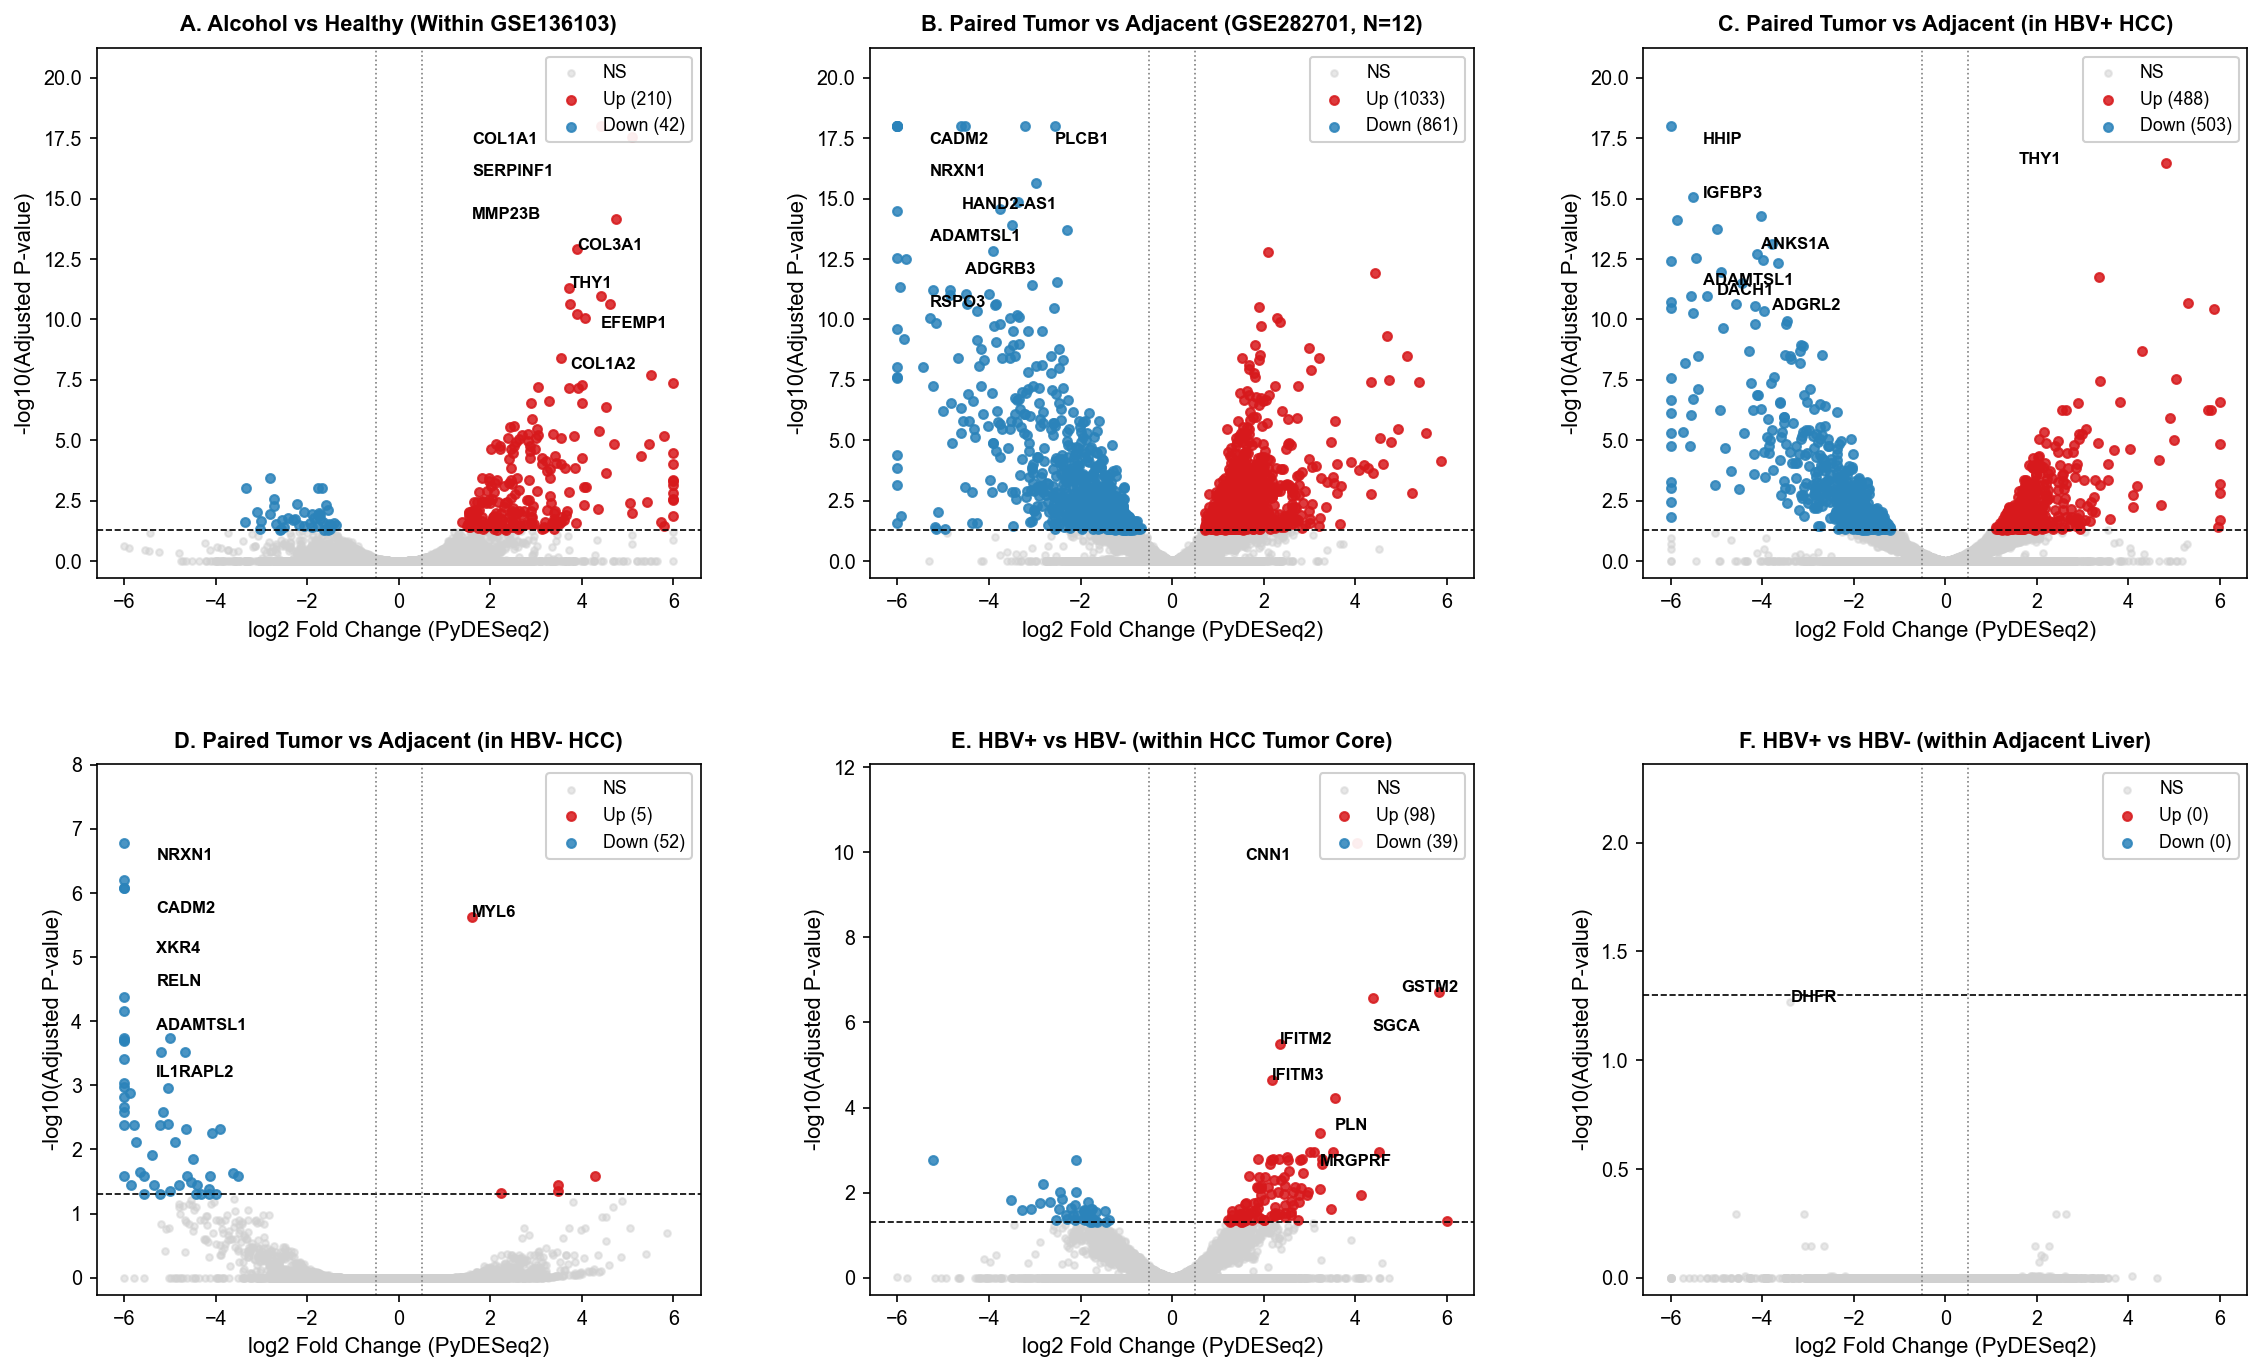

In [9]:
from pydeseq2.dds import DeseqDataSet
from pydeseq2.ds import DeseqStats

X_cnt = adata.layers["counts"].tocsr()
obs_df = adata.obs.copy()

pb_dict, pb_meta = {}, []
for s_bio_id, idx in obs_df.groupby("sample_bio_id", observed=True).groups.items():
    pos = obs_df.index.get_indexer(idx)
    pb_dict[s_bio_id] = np.asarray(X_cnt[pos].sum(axis=0)).ravel().astype(int)
    row0 = obs_df.iloc[pos[0]]
    pb_meta.append({
        "sample_bio_id": s_bio_id,
        "global_patient_id": row0["global_patient_id"],
        "dataset_id": row0["dataset_id"],
        "tissue_context": row0["tissue_context"],
        "etiology": row0["etiology"],
        "condition_group": row0["condition_group"],
        "n_cells": len(pos),
    })

df_pb_counts = pd.DataFrame(pb_dict, index=adata.var_names).T
df_pb_meta   = pd.DataFrame(pb_meta).set_index("sample_bio_id")

# Filter out technical artifact genes (MT-, Ribosomal, Heat-shock) & low-count genes BEFORE DESeq2
clean_gene_mask = ~df_pb_counts.columns.str.match(r"^(MT-|RPL|RPS|MRP|HSP|DNAJ|MTRNR)")
df_pb_counts = df_pb_counts.loc[:, clean_gene_mask]
keep_expr = (df_pb_counts >= 10).sum(axis=0) >= 3
df_pb_counts = df_pb_counts.loc[:, keep_expr]
print(f"[VERIFIED] Pseudobulk Matrix: {df_pb_counts.shape[0]} Biological Samples × {df_pb_counts.shape[1]:,} Clean Genes.")

all_deg_tables = []

def run_deseq_contrast(counts_sub, meta_sub, design_cols, contrast_tuple, label):
    dds_sub = DeseqDataSet(
        counts=counts_sub,
        metadata=meta_sub,
        design_factors=design_cols,
        refit_cooks=True,
        n_cpus=4,
    )
    dds_sub.deseq2()
    st = DeseqStats(dds_sub, contrast=contrast_tuple, n_cpus=4)
    st.summary()
    res = st.results_df.copy()
    res["gene"] = res.index
    res["contrast_label"] = label
    res = res.dropna(subset=["log2FoldChange", "pvalue"]).sort_values("pvalue")
    n_sig = ((res["padj"] < 0.05) & (res["log2FoldChange"].abs() > 0.5)).sum()
    print(f"[PyDESeq2] {label:<55} | DEGs (FDR<0.05, |LFC|>0.5): {n_sig:>4}")
    return res

# Contrast 1: Exploratory Within-GSE136103 Alcohol vs Healthy
m_136 = df_pb_meta["dataset_id"] == "GSE136103"
meta_136 = df_pb_meta.loc[m_136 & df_pb_meta["condition_group"].isin(["Alcohol", "Healthy"])].copy()
cnt_136  = df_pb_counts.loc[meta_136.index]
all_deg_tables.append(
    run_deseq_contrast(cnt_136, meta_136, "condition_group", ["condition_group", "Alcohol", "Healthy"], "A. Alcohol vs Healthy (Within GSE136103)")
)

# Contrast 2: All Paired Tumor vs Adjacent in GSE282701 (N=12 samples from 6 matched patients)
m_282 = df_pb_meta["dataset_id"] == "GSE282701"
meta_282 = df_pb_meta.loc[m_282].copy()
cnt_282  = df_pb_counts.loc[meta_282.index]
all_deg_tables.append(
    run_deseq_contrast(
        cnt_282, meta_282,
        ["global_patient_id", "tissue_context"],
        ["tissue_context", "Tumor_Core", "Adjacent_Liver"],
        f"B. Paired Tumor vs Adjacent (GSE282701, N={len(meta_282)})",
    )
)

# Contrasts 3 & 4: Patient-Paired Tumor vs Adjacent stratified by HBV status (includes global_patient_id pairing!)
for etio_val, lbl in [
    ("HBV_pos", "C. Paired Tumor vs Adjacent (in HBV+ HCC)"),
    ("HBV_neg", "D. Paired Tumor vs Adjacent (in HBV- HCC)"),
]:
    sub_m = meta_282[meta_282["etiology"] == etio_val].copy()
    sub_c = cnt_282.loc[sub_m.index]
    all_deg_tables.append(
        run_deseq_contrast(
            sub_c, sub_m,
            ["global_patient_id", "tissue_context"],
            ["tissue_context", "Tumor_Core", "Adjacent_Liver"],
            lbl,
        )
    )

# Contrasts 5 & 6: HBV+ vs HBV- within Tumor Core and within Adjacent Liver
for tc_val, test_g, ref_g, lbl in [
    ("Tumor_Core",     "HBV_pos_Tumor",    "HBV_neg_Tumor",    "E. HBV+ vs HBV- (within HCC Tumor Core)"),
    ("Adjacent_Liver", "HBV_pos_Adjacent", "HBV_neg_Adjacent", "F. HBV+ vs HBV- (within Adjacent Liver)"),
]:
    sub_m = meta_282[meta_282["tissue_context"] == tc_val].copy()
    sub_c = cnt_282.loc[sub_m.index]
    all_deg_tables.append(
        run_deseq_contrast(sub_c, sub_m, "condition_group", ["condition_group", test_g, ref_g], lbl)
    )

df_all_degs = pd.concat(all_deg_tables, ignore_index=True)
df_all_degs.to_csv(os.path.join(TAB_DIR, "Table4_Pseudobulk_PyDESeq2_Rigorous_Deconfounded.csv"), index=False)

# Plot Figure 4: 6-Panel Volcano Plots
fig, axes = plt.subplots(2, 3, figsize=(18.5, 10.8))
plt.subplots_adjust(wspace=0.28, hspace=0.35)
axes_flat = axes.flatten()

for idx, res in enumerate(all_deg_tables):
    ax = axes_flat[idx]
    lbl = res["contrast_label"].iloc[0]
    lfc = res["log2FoldChange"].clip(-6, 6)
    p_y = -np.log10(res["padj"].fillna(1.0).clip(lower=1e-18))

    sig_up = (res["padj"] < 0.05) & (res["log2FoldChange"] > 0.5)
    sig_dn = (res["padj"] < 0.05) & (res["log2FoldChange"] < -0.5)

    ax.scatter(lfc[~(sig_up | sig_dn)], p_y[~(sig_up | sig_dn)], c="#d0d0d0", s=10, alpha=0.5, label="NS")
    ax.scatter(lfc[sig_up], p_y[sig_up], c="#d7191c", s=18, alpha=0.85, label=f"Up ({sig_up.sum()})")
    ax.scatter(lfc[sig_dn], p_y[sig_dn], c="#2b83ba", s=18, alpha=0.85, label=f"Down ({sig_dn.sum()})")

    y_max_val = max(p_y.max(), 2.0)
    ax.set_ylim(-0.04 * y_max_val, y_max_val * 1.18)
    ax.set_xlim(-6.6, 6.6)

    top_g = res.nsmallest(7, "padj")
    placed_coords = []
    for _, r in top_g.iterrows():
        if r["padj"] < 0.25:
            tx = float(np.clip(r["log2FoldChange"], -5.3, 5.0))
            ty = float(min(-np.log10(max(r["padj"], 1e-18)), y_max_val * 0.96))
            # Avoid legend box in upper right (x > 2.2 and ty > 0.78 * y_max_val)
            if tx > 2.2 and ty > 0.78 * y_max_val:
                tx = 1.6
            # Stagger vertically & horizontally if another gene label is too close
            for px, py in placed_coords:
                if abs(tx - px) < 1.45 and abs(ty - py) < 0.065 * y_max_val:
                    ty -= 0.075 * y_max_val
            placed_coords.append((tx, ty))
            ax.text(tx, max(ty, 0.2), r["gene"], fontsize=8.0, fontweight="bold")

    ax.axhline(-np.log10(0.05), color="black", linestyle="--", linewidth=0.8)
    ax.axvline(0.5, color="grey", linestyle=":", linewidth=0.8)
    ax.axvline(-0.5, color="grey", linestyle=":", linewidth=0.8)
    ax.set_title(lbl, fontweight="bold", fontsize=10.5, pad=8)
    ax.set_xlabel("log2 Fold Change (PyDESeq2)")
    ax.set_ylabel("-log10(Adjusted P-value)")
    ax.legend(loc="upper right", fontsize=8.5, frameon=True, framealpha=0.92)

save_pub_fig("Fig5_Deconfounded_Pseudobulk_Volcano_Plots.png")

2026-11-12 17:40:54,893 [WARNING] Duplicated values found in preranked stats: 1.92% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-12 17:40:55,437 [WARNING] Duplicated values found in preranked stats: 0.12% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-12 17:40:56,018 [WARNING] Duplicated values found in preranked stats: 0.53% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-12 17:40:56,608 [WARNING] Duplicated values found in preranked stats: 0.68% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-12 17:40:57,230 [WARNING] Duplicated values found in preranked stats: 0.16% of genes
The order of those genes will be arbitrary, which may produce unexpected results.
2026-11-12 17:40:57,809 [WARNING] Duplicated values found in preranked stats: 6.69% of genes
The order of those genes will be

[VERIFIED] Saved Table 5 with 294 Hallmark pathway enrichment records (1,000 permutations).


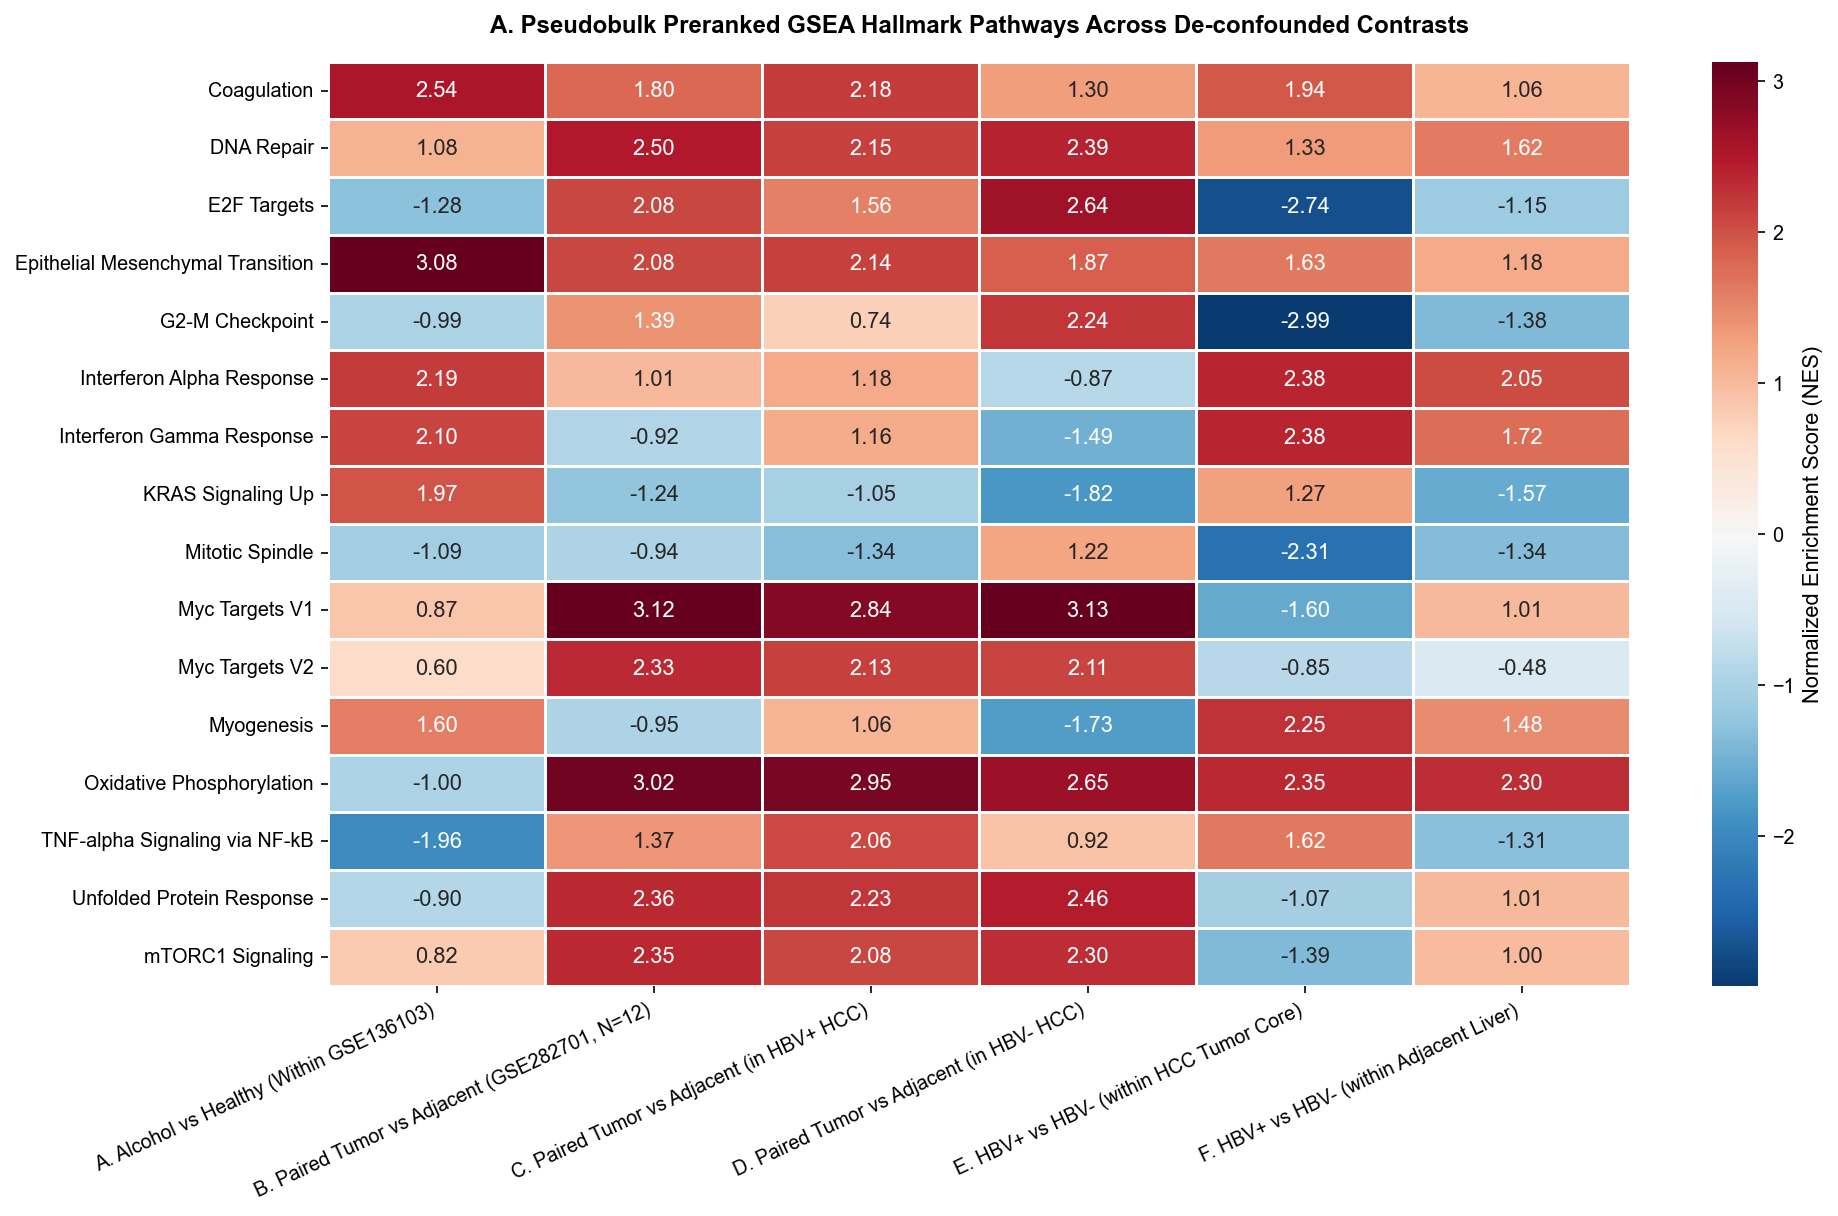

,State_Pair,Full_Atlas_Connectivity,Bootstrap_Mean,Bootstrap_SD,Stability_Freq (>0.05)
5,A2 <-> INF,0.835,0.836,0.012,1.0
0,qHSC <-> A1,0.724,0.726,0.013,1.0
2,qHSC <-> INF,0.684,0.682,0.012,1.0
4,A1 <-> INF,0.591,0.592,0.014,1.0
1,qHSC <-> A2,0.362,0.363,0.009,1.0
3,A1 <-> A2,0.244,0.244,0.007,1.0


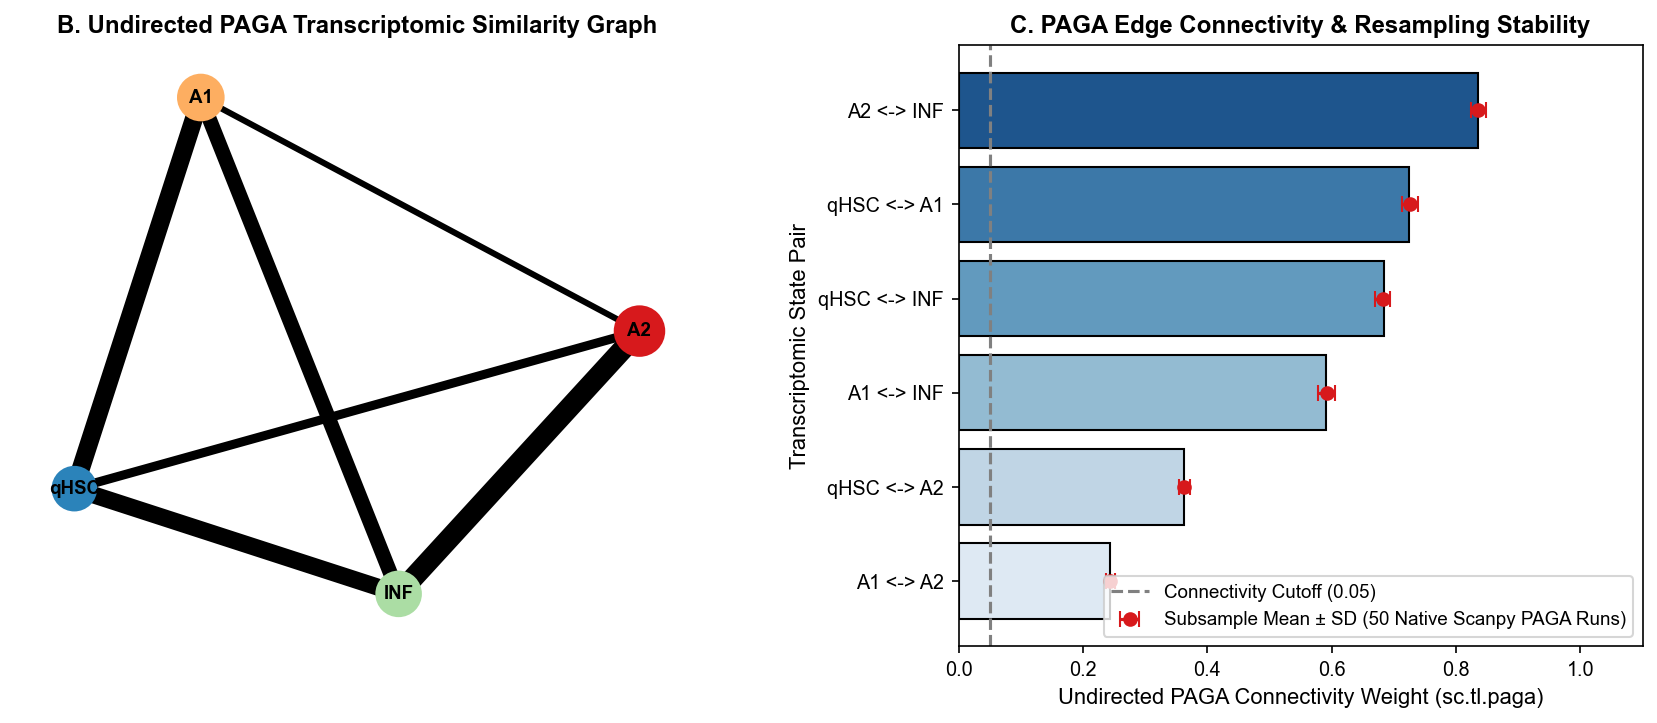

In [ ]:
# GSEA on Pseudobulk Wald Statistics 
gsea_records = []
for res in all_deg_tables:
    lbl = res["contrast_label"].iloc[0]
    df_valid = res[["gene", "stat", "log2FoldChange"]].replace([np.inf, -np.inf], np.nan).dropna()
    df_valid = df_valid.drop_duplicates(subset=["gene"]).copy()

    df_valid["stat_ranked"] = df_valid["stat"] + 1e-9 * df_valid["log2FoldChange"]
    df_valid = df_valid.sort_values("stat_ranked", ascending=False)
    rnk_series = pd.Series(df_valid["stat_ranked"].values, index=df_valid["gene"].values)

    pre_res = gp.prerank(
        rnk=rnk_series,
        gene_sets="MSigDB_Hallmark_2020",
        processes=4,
        permutation_num=1000,
        seed=RANDOM_STATE,
        verbose=False,
    )
    df_g = pre_res.res2d[["Term", "ES", "NES", "NOM p-val", "FDR q-val", "Lead_genes"]].copy()
    df_g["Contrast"] = lbl
    gsea_records.append(df_g)

df_gsea_all = pd.concat(gsea_records, ignore_index=True)
df_gsea_all.to_csv(os.path.join(TAB_DIR, "Table5_Pseudobulk_GSEA_Hallmark_Pathways.csv"), index=False)
print(f"[VERIFIED] Saved Table 5 with {len(df_gsea_all)} Hallmark pathway enrichment records (1,000 permutations).")

df_gsea_all["NES"] = pd.to_numeric(df_gsea_all["NES"], errors="coerce")
top_pathways = df_gsea_all.groupby("Term")["NES"].apply(lambda x: np.max(np.abs(x))).nlargest(16).index
piv_gsea = df_gsea_all[df_gsea_all["Term"].isin(top_pathways)].pivot(index="Term", columns="Contrast", values="NES").fillna(0.0)
piv_gsea.index = [t.replace("Hallmark ", "") for t in piv_gsea.index]

fig5, ax5 = plt.subplots(figsize=(14.0, 8.0))
sns.heatmap(
    piv_gsea, annot=True, fmt=".2f", cmap="RdBu_r", center=0,
    linewidths=0.5, cbar_kws={"label": "Normalized Enrichment Score (NES)"}, ax=ax5
)
ax5.set_title("A. Pseudobulk Preranked GSEA Hallmark Pathways Across De-confounded Contrasts", fontweight="bold", pad=14)
ax5.set_ylabel("")
ax5.set_xlabel("")
plt.xticks(rotation=25, ha="right")
save_pub_fig("Fig6A_Pseudobulk_GSEA_Hallmark_Heatmap.png")

# Undirected PAGA Transcriptomic Connectivity & Native Scanpy Subsampling Stability (50 Resamples)
sc.pp.neighbors(adata, use_rep="X_harmony", n_neighbors=25, random_state=RANDOM_STATE)
sc.tl.paga(adata, groups="HSC_state")
base_conn = adata.uns["paga"]["connectivities"].toarray()
states_list = ["qHSC", "A1", "A2", "INF"]
n_states = len(states_list)

def run_native_scanpy_paga(adata_obj: ad.AnnData, sub_indices: np.ndarray, n_nb: int = 20) -> np.ndarray:
    ad_sub = adata_obj[sub_indices].copy()
    ad_sub.obs["HSC_state"] = pd.Categorical(ad_sub.obs["HSC_state"], categories=states_list, ordered=True)
    sc.pp.neighbors(ad_sub, use_rep="X_harmony", n_neighbors=min(n_nb, ad_sub.n_obs - 2), random_state=RANDOM_STATE)
    sc.tl.paga(ad_sub, groups="HSC_state")
    return ad_sub.uns["paga"]["connectivities"].toarray()

n_boot = 50
boot_mats = []
for b in range(n_boot):
    rng = np.random.default_rng(RANDOM_STATE + b)
    sub_idx = np.sort(rng.choice(adata.n_obs, size=int(0.80 * adata.n_obs), replace=False))
    boot_mats.append(run_native_scanpy_paga(adata, sub_idx, n_nb=20))

boot_stack = np.stack(boot_mats, axis=0)
boot_mean  = np.mean(boot_stack, axis=0)
boot_sd    = np.std(boot_stack, axis=0)

edge_rows = []
for i in range(n_states):
    for j in range(i + 1, n_states):
        edge_rows.append({
            "State_Pair": f"{states_list[i]} <-> {states_list[j]}",
            "Full_Atlas_Connectivity": round(float(base_conn[i, j]), 3),
            "Bootstrap_Mean": round(float(boot_mean[i, j]), 3),
            "Bootstrap_SD": round(float(boot_sd[i, j]), 3),
            "Stability_Freq (>0.05)": round(float(np.mean(boot_stack[:, i, j] > 0.05)), 2),
        })

df_paga_boot = pd.DataFrame(edge_rows).sort_values("Full_Atlas_Connectivity", ascending=False)
df_paga_boot.to_csv(os.path.join(TAB_DIR, "Table6_PAGA_Undirected_Bootstrap_Stability.csv"), index=False)
display(df_paga_boot)

fig6, axes6 = plt.subplots(1, 2, figsize=(14.0, 5.2))
plt.subplots_adjust(wspace=0.38)

sc.pl.paga(
    adata, color="HSC_state", threshold=0.05, node_size_scale=2.8,
    edge_width_scale=1.6, ax=axes6[0], show=False, frameon=False,
    title="B. Undirected PAGA Transcriptomic Similarity Graph",
)
axes6[0].set_title("B. Undirected PAGA Transcriptomic Similarity Graph", fontweight="bold")
sns.barplot(
    data=df_paga_boot, x="Full_Atlas_Connectivity", y="State_Pair",
    palette="Blues_r", edgecolor="black", ax=axes6[1],
)
axes6[1].errorbar(
    x=df_paga_boot["Bootstrap_Mean"], y=np.arange(len(df_paga_boot)),
    xerr=df_paga_boot["Bootstrap_SD"], fmt="o", color="#d7191c",
    capsize=4, label="Subsample Mean ± SD (50 Native Scanpy PAGA Runs)",
)
axes6[1].axvline(0.05, color="grey", linestyle="--", label="Connectivity Cutoff (0.05)")
axes6[1].set_title("C. PAGA Edge Connectivity & Resampling Stability", fontweight="bold")
axes6[1].set_xlabel("Undirected PAGA Connectivity Weight (sc.tl.paga)")
axes6[1].set_ylabel("Transcriptomic State Pair")
axes6[1].set_xlim(0, 1.10)
axes6[1].legend(loc="lower right", frameon=False)

Tissue_Context,Adjacent_Liver,NonTumor_Liver,Tumor_Core
State_Pair,,,
A1 <-> A2,0.146,0.563,0.252
A1 <-> INF,0.500,0.769,0.556
A2 <-> INF,0.967,0.906,0.929
qHSC <-> A1,0.354,0.723,1.000
qHSC <-> A2,0.405,0.965,0.245
qHSC <-> INF,0.728,0.895,0.521


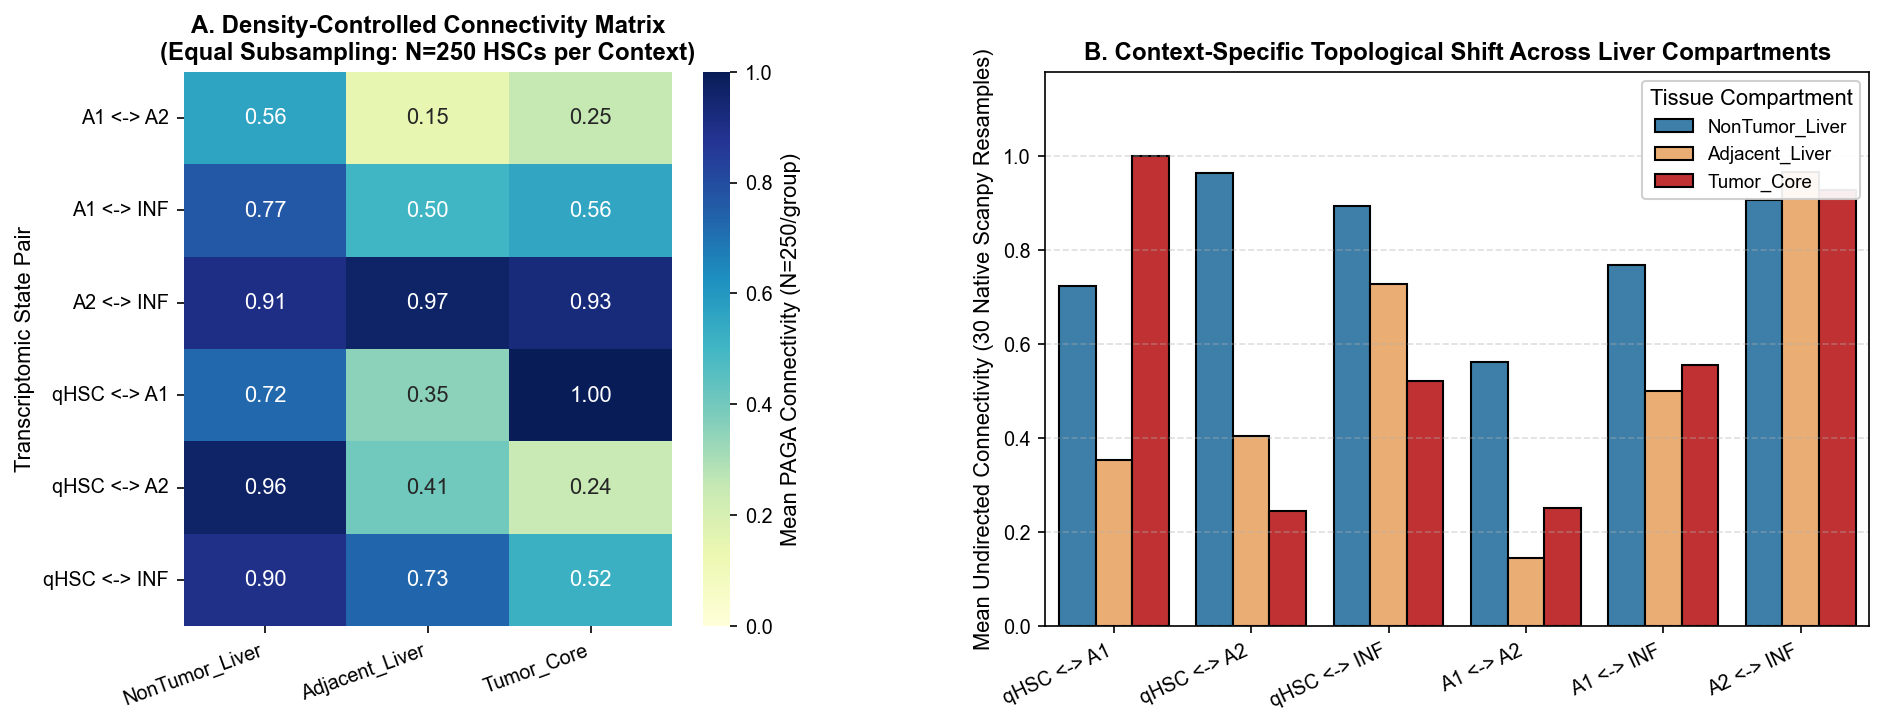

In [ ]:
tissue_groups = ["NonTumor_Liver", "Adjacent_Liver", "Tumor_Core"]
states_list   = ["qHSC", "A1", "A2", "INF"]
n_eq = min(250, int(adata.obs["tissue_context"].value_counts().min()))
n_rep = 30

tiss_paga_records = []
for tc in tissue_groups:
    tc_indices = np.where((adata.obs["tissue_context"] == tc).values)[0]
    mats_tc = []
    for r in range(n_rep):
        rng = np.random.default_rng(RANDOM_STATE + 100 * r)
        sub_idx = np.sort(rng.choice(tc_indices, size=n_eq, replace=False))
        mats_tc.append(run_native_scanpy_paga(adata, sub_idx, n_nb=15))
    mat_mean = np.mean(np.stack(mats_tc, axis=0), axis=0)
    mat_sd   = np.std(np.stack(mats_tc, axis=0), axis=0)

    for i in range(len(states_list)):
        for j in range(i + 1, len(states_list)):
            tiss_paga_records.append({
                "Tissue_Context": tc,
                "Equal_Sampled_Cells": n_eq,
                "State_Pair": f"{states_list[i]} <-> {states_list[j]}",
                "Connectivity_Mean": round(float(mat_mean[i, j]), 3),
                "Connectivity_SD": round(float(mat_sd[i, j]), 3),
            })

df_supp_paga = pd.DataFrame(tiss_paga_records)
df_supp_paga.to_csv(os.path.join(TAB_DIR, "Supplementary_TableS1_Density_Controlled_Tissue_PAGA.csv"), index=False)
display(df_supp_paga.pivot(index="State_Pair", columns="Tissue_Context", values="Connectivity_Mean"))

fig_s1, axes_s1 = plt.subplots(1, 2, figsize=(14.5, 4.8), gridspec_kw={"width_ratios": [1.0, 1.35]})
plt.subplots_adjust(wspace=0.35)

piv_s1 = df_supp_paga.pivot(index="State_Pair", columns="Tissue_Context", values="Connectivity_Mean")[tissue_groups]
sns.heatmap(piv_s1, annot=True, fmt=".2f", cmap="YlGnBu", vmin=0.0, vmax=1.0, cbar_kws={"label": "Mean PAGA Connectivity (N=250/group)"}, ax=axes_s1[0])
axes_s1[0].set_title(f"A. Density-Controlled Connectivity Matrix\n(Equal Subsampling: N={n_eq} HSCs per Context)", fontweight="bold")
axes_s1[0].set_xlabel("")
axes_s1[0].set_ylabel("Transcriptomic State Pair")
axes_s1[0].set_xticklabels(tissue_groups, rotation=20, ha="right")

sns.barplot(
    data=df_supp_paga, x="State_Pair", y="Connectivity_Mean", hue="Tissue_Context",
    hue_order=tissue_groups, palette=["#2b83ba", "#fdae61", "#d7191c"], edgecolor="black", ax=axes_s1[1]
)
axes_s1[1].set_title("B. Context-Specific Topological Shift Across Liver Compartments", fontweight="bold")
axes_s1[1].set_ylabel("Mean Undirected Connectivity (30 Native Scanpy Resamples)")
axes_s1[1].set_xlabel("")
axes_s1[1].set_xticklabels(axes_s1[1].get_xticklabels(), rotation=25, ha="right")
axes_s1[1].set_ylim(0, 1.18)
axes_s1[1].legend(title="Tissue Compartment", loc="upper right", frameon=True, framealpha=0.92)
axes_s1[1].grid(axis="y", linestyle="--", alpha=0.4)

=== [1] SYNCHRONIZED SAMPLE-LEVEL STATE PROPORTIONS (N = 34 BIO SAMPLES) ===


,Condition_Group,N_Bio_Samples,Total_Cells,qHSC_Mean_SD (%),qHSC_Median_IQR (%),A1_Mean_SD (%),A1_Median_IQR (%),A2_Mean_SD (%),A2_Median_IQR (%),INF_Mean_SD (%),INF_Median_IQR (%)
0,Healthy,17,1978,25.0 ± 8.5,25.0 (19.2-28.9),28.7 ± 15.1,25.0 (17.9-39.1),18.0 ± 9.4,17.3 (13.6-21.8),28.3 ± 16.2,25.0 (16.7-39.1)
1,NAFLD,1,188,30.3 ± 0.0,30.3 (30.3-30.3),34.0 ± 0.0,34.0 (34.0-34.0),23.4 ± 0.0,23.4 (23.4-23.4),12.2 ± 0.0,12.2 (12.2-12.2)
2,Alcohol,2,222,20.2 ± 9.9,20.2 (16.7-23.6),28.4 ± 0.2,28.4 (28.4-28.5),41.0 ± 15.5,41.0 (35.5-46.5),10.4 ± 5.4,10.4 (8.5-12.4)
3,HBV_neg_Adjacent,3,83,54.5 ± 8.8,50.0 (49.4-57.4),30.1 ± 18.1,25.6 (20.1-37.8),0.0 ± 0.0,0.0 (0.0-0.0),15.4 ± 13.6,20.6 (10.3-23.1)
4,HBV_pos_Adjacent,3,181,69.3 ± 17.6,69.8 (60.6-78.2),22.2 ± 16.8,19.8 (13.2-29.9),1.0 ± 1.6,0.0 (0.0-1.4),7.6 ± 2.4,6.7 (6.2-8.5)
5,HBV_neg_Tumor,3,2259,46.6 ± 35.7,64.5 (35.0-67.2),13.1 ± 8.5,16.1 (9.8-18.0),25.2 ± 35.9,9.4 (4.7-37.8),15.0 ± 12.4,19.4 (10.2-22.0)
6,HBV_pos_Tumor,3,619,15.8 ± 10.5,10.3 (9.8-19.1),54.8 ± 16.0,59.3 (48.1-63.6),10.7 ± 6.4,11.1 (7.6-14.0),18.7 ± 18.0,20.4 (10.2-28.1)
7,HCC_Tumor,2,198,19.8 ± 24.2,19.8 (11.2-28.3),42.0 ± 33.7,42.0 (30.0-53.9),21.7 ± 4.7,21.7 (20.1-23.4),16.6 ± 4.8,16.6 (14.9-18.3)



=== [2] CELL-COUNT INVARIANT & WITHIN-STATE PAIRED REPROGRAMMING AUDIT (WITH BH-FDR) ===


,Analysis_Scope,Feature,Median_Cells_Per_Donor (Adj/Tum),Adjacent_Mean,Tumor_Mean,Mean_Paired_Delta,Concordant_Donors,Paired_Wilcoxon_P,Within_Scope_BH_FDR
0,1. All_HSCs (Cell-Count Invariant Mean),Score_Desmoplastic_ECM,34/169,0.565,1.354,0.789,6/6,0.0312,0.0625
1,1. All_HSCs (Cell-Count Invariant Mean),Score_Quiescence_Core,34/169,0.586,0.056,-0.530,5/6,0.0625,0.0893
2,1. All_HSCs (Cell-Count Invariant Mean),Score_Anabolic_MYC_UPR,34/169,-0.061,0.145,0.206,6/6,0.0312,0.0625
3,1. All_HSCs (Cell-Count Invariant Mean),COL1A1,34/169,1.094,2.299,1.205,5/6,0.1562,0.1736
4,1. All_HSCs (Cell-Count Invariant Mean),POSTN,34/169,0.259,0.211,-0.048,3/6,1.0000,1.0000
5,1. All_HSCs (Cell-Count Invariant Mean),SPARC,34/169,1.984,3.237,1.254,6/6,0.0312,0.0625
6,1. All_HSCs (Cell-Count Invariant Mean),LGALS1,34/169,2.071,3.267,1.197,6/6,0.0312,0.0625
7,1. All_HSCs (Cell-Count Invariant Mean),LRAT,34/169,0.214,0.009,-0.205,5/6,0.0625,0.0893
8,1. All_HSCs (Cell-Count Invariant Mean),RELN,34/169,0.990,0.012,-0.978,6/6,0.0312,0.0625
9,1. All_HSCs (Cell-Count Invariant Mean),RBP1,34/169,1.275,0.783,-0.492,5/6,0.0938,0.1172


Fitting size factors...
... done in 0.00 seconds.



Using None as control genes, passed at DeseqDataSet initialization


Fitting dispersions...
... done in 0.94 seconds.

Fitting dispersion trend curve...
... done in 0.11 seconds.

Fitting MAP dispersions...
... done in 1.12 seconds.

Fitting LFCs...
... done in 0.96 seconds.

Calculating cook's distance...
... done in 0.00 seconds.

Replacing 0 outlier genes.

Running Wald tests...


Log2 fold change & Wald test p-value: tissue_context Tumor_Core vs Adjacent_Liver
             baseMean  log2FoldChange     lfcSE      stat    pvalue      padj
FAM41C       0.104202       -2.805739  4.368136 -0.642320  0.520666       NaN
SAMD11       9.273516       -3.665794  0.917793 -3.994139  0.000065  0.002147
NOC2L       10.517423        0.507293  0.623388  0.813767  0.415779  0.686473
HES4        68.031560        1.967547  0.606322  3.245055  0.001174  0.019068
ISG15       94.572642        1.912356  0.548758  3.484883  0.000492  0.010139
...               ...             ...       ...       ...       ...       ...
S100B       27.268991       -8.473562  3.865300 -2.192213  0.028364  0.156827
PRMT2       38.249608        0.391133  0.420670  0.929787  0.352482  0.630317
AL592183.1  10.292036       -0.386537  0.579790 -0.666683  0.504974  0.753013
AC007325.4   5.084657       -0.180881  0.937922 -0.192852  0.847074       NaN
AC240274.1   3.443208       -1.976272  0.998284 -1.979669  0

... done in 0.35 seconds.



,LRAT,RGS5,COL1A1,PTPRC,CD3D,CD68,ALB,EPCAM,IFITM2,IFITM3,IFI27,ISG15,STAT1,OAS1
State_x_HBV,,,,,,,,,,,,,,
qHSC (HBV_neg),0.042,2.948,1.385,0.0,0.009,0.039,0.964,0.0,1.157,2.255,0.494,0.385,0.202,0.064
qHSC (HBV_pos),0.285,2.593,1.370,0.0,0.020,0.080,0.362,0.0,2.285,3.542,1.358,0.899,0.257,0.174
A1 (HBV_neg),0.000,2.384,1.887,0.0,0.010,0.032,0.535,0.0,1.365,2.231,0.486,0.540,0.249,0.028
A1 (HBV_pos),0.000,3.520,1.412,0.0,0.027,0.030,0.373,0.0,2.614,3.733,1.423,0.907,0.174,0.063
A2 (HBV_neg),0.000,0.098,4.879,0.0,0.002,0.117,0.032,0.0,1.047,2.065,0.308,0.365,0.223,0.056
A2 (HBV_pos),0.000,1.417,4.185,0.0,0.025,0.175,0.499,0.0,2.374,3.758,1.015,1.027,0.258,0.129
INF (HBV_neg),0.005,0.126,3.331,0.0,0.013,0.156,0.059,0.0,1.067,2.112,0.392,0.427,0.210,0.086
INF (HBV_pos),0.037,2.359,2.804,0.0,0.031,0.074,0.613,0.0,2.545,3.626,1.040,1.201,0.227,0.128


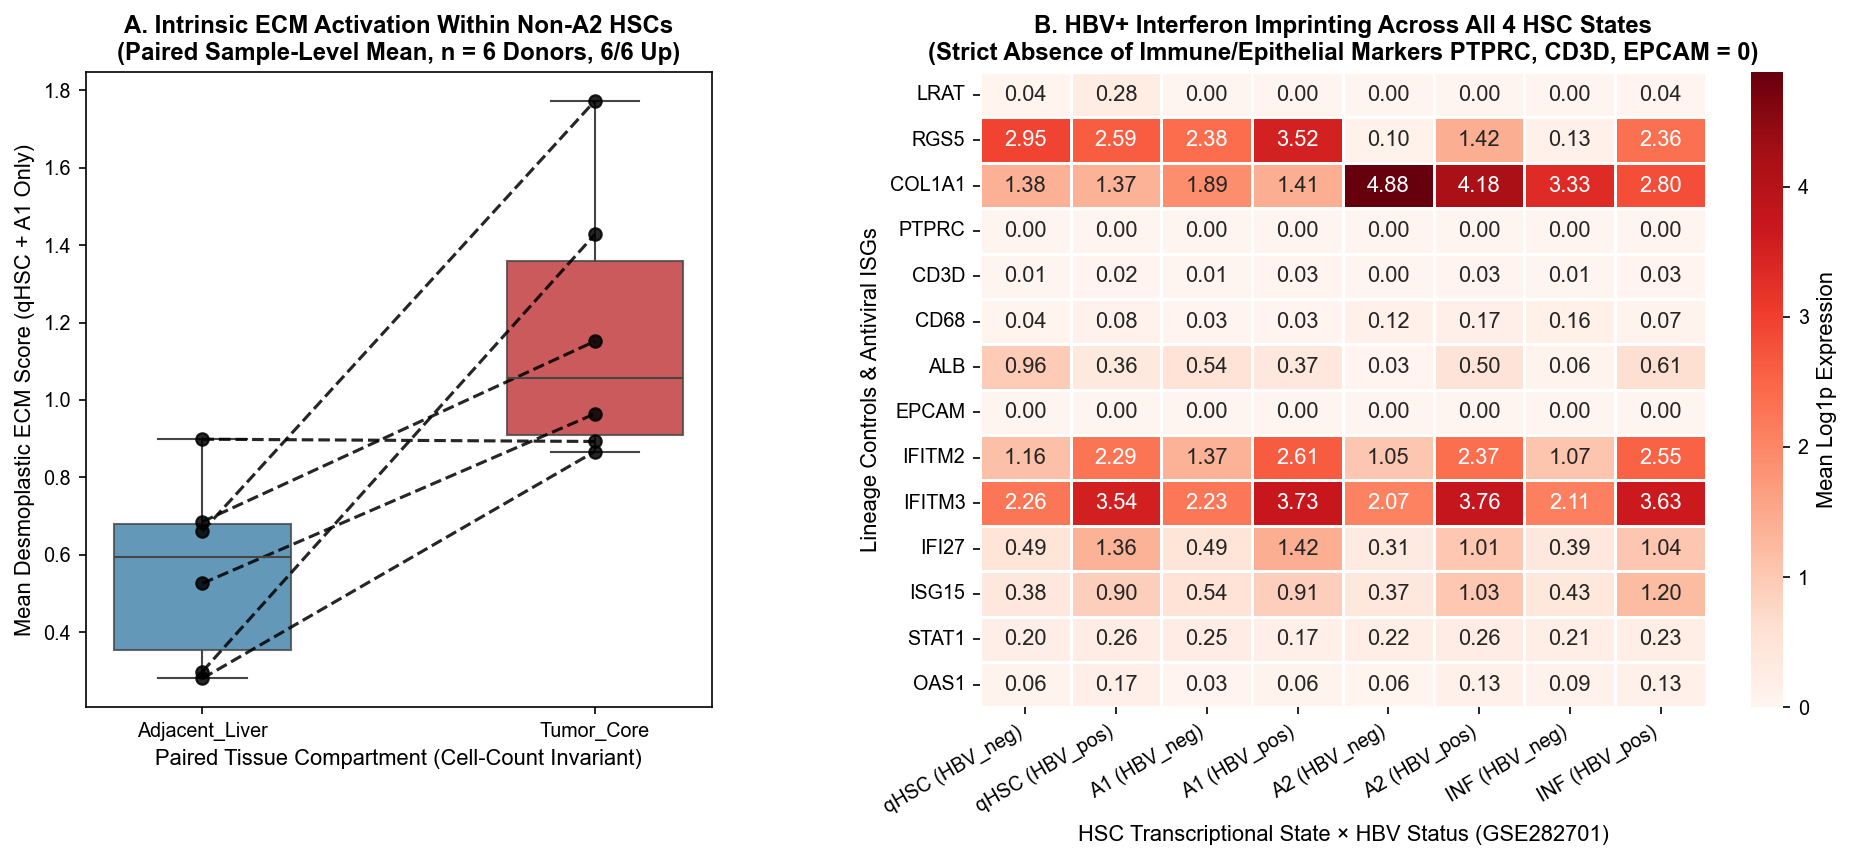


[VERIFIED PIPELINE COMPLETE] All figures, main tables, and supplementary tables saved to: ./data/raw/INTEGRATED_HSC


In [ ]:
STATE_COL = "HSC_state"

# 1. Sample-Level State Proportion Summary Table (Mean ± SD & Median [IQR], N=34)
sync_rows = []
for grp in order_cond:
    df_g = df_bio_summary[df_bio_summary["condition_group"] == grp]
    if len(df_g) == 0:
        continue
    row = {"Condition_Group": grp, "N_Bio_Samples": len(df_g), "Total_Cells": int(df_g["total_HSCs"].sum())}
    for st in ["qHSC", "A1", "A2", "INF"]:
        vals = df_g[st].values
        mean_v, sd_v = np.mean(vals), np.std(vals, ddof=1) if len(vals) > 1 else 0.0
        q25, med_v, q75 = np.percentile(vals, [25, 50, 75])
        row[f"{st}_Mean_SD (%)"]    = f"{mean_v:.1f} ± {sd_v:.1f}"
        row[f"{st}_Median_IQR (%)"] = f"{med_v:.1f} ({q25:.1f}-{q75:.1f})"
    sync_rows.append(row)

df_tab_sync = pd.DataFrame(sync_rows)
df_tab_sync.to_csv(os.path.join(TAB_DIR, "Supplementary_TableS2_SampleLevel_State_Proportions_Summary.csv"), index=False)
print("=== [1] SYNCHRONIZED SAMPLE-LEVEL STATE PROPORTIONS (N = 34 BIO SAMPLES) ===")
display(df_tab_sync)

# 2. Cell-Count Invariant & Within-State Paired Tumor vs Adjacent Audit (n=6 Donors, with BH-FDR)
ad_282 = adata[adata.obs["dataset_id"] == "GSE282701"].copy()

SIG_PANELS_P1 = {
    "Desmoplastic_ECM": ["COL1A1", "COL1A2", "COL3A1", "POSTN", "SPARC", "THY1", "SERPINE1", "TIMP1", "LGALS1"],
    "Quiescence_Core":  ["LRAT", "RELN", "RBP1", "COLEC11", "VIPR1"],
    "Anabolic_MYC_UPR": ["MYC", "NPM1", "ENO1", "LDHA", "CYCS", "COX5A", "ATP5F1A", "HSPA5", "HSP90B1", "XBP1"],
}
for sig_name, g_list in SIG_PANELS_P1.items():
    valid_g = [g for g in g_list if g in ad_282.raw.var_names]
    sc.tl.score_genes(ad_282, gene_list=valid_g, score_name=f"Score_{sig_name}", use_raw=True, random_state=RANDOM_STATE)

raw_df = pd.DataFrame(
    ad_282.raw.X.toarray() if sp.issparse(ad_282.raw.X) else ad_282.raw.X,
    index=ad_282.obs_names, columns=ad_282.raw.var_names
)
key_genes_p1 = [g for g in ["COL1A1", "POSTN", "SPARC", "LGALS1", "LRAT", "RELN", "RBP1"] if g in raw_df.columns]
score_cols_p1 = [f"Score_{k}" for k in SIG_PANELS_P1.keys()]

for sc_col in score_cols_p1:
    raw_df[sc_col] = ad_282.obs[sc_col].values

raw_df["patient_id"]     = ad_282.obs["global_patient_id"].values
raw_df["tissue_context"] = ad_282.obs["tissue_context"].values
raw_df["state"]          = ad_282.obs[STATE_COL].astype(str).values

paired_audit_rows = []
subsets_to_test = {
    "1. All_HSCs (Cell-Count Invariant Mean)": raw_df,
    "2. Within_Non_A2_States (qHSC + A1 Only)": raw_df[raw_df["state"].isin(["qHSC", "A1"])],
    "3. Within_A1_Contractile_Only": raw_df[raw_df["state"] == "A1"],
}
features_to_test = score_cols_p1 + key_genes_p1

for sub_name, sub_df in subsets_to_test.items():
    pb_mean = sub_df.groupby(["patient_id", "tissue_context"], observed=True)[features_to_test].mean().unstack("tissue_context")
    cell_cnts = sub_df.groupby(["patient_id", "tissue_context"], observed=True).size().unstack("tissue_context", fill_value=0)
    med_adj_c = int(np.median(cell_cnts["Adjacent_Liver"])) if "Adjacent_Liver" in cell_cnts else 0
    med_tum_c = int(np.median(cell_cnts["Tumor_Core"])) if "Tumor_Core" in cell_cnts else 0

    scope_rows = []
    for feat in features_to_test:
        if ("Tumor_Core" in pb_mean[feat].columns) and ("Adjacent_Liver" in pb_mean[feat].columns):
            paired_df = pb_mean[feat][["Adjacent_Liver", "Tumor_Core"]].dropna()
            if len(paired_df) >= 5:
                diff = paired_df["Tumor_Core"] - paired_df["Adjacent_Liver"]
                _, p_wilcox = wilcoxon(paired_df["Tumor_Core"], paired_df["Adjacent_Liver"], zero_method="zsplit")
                n_conc = int((diff > 0).sum()) if diff.mean() >= 0 else int((diff < 0).sum())
                scope_rows.append({
                    "Analysis_Scope": sub_name,
                    "Feature": feat,
                    "Median_Cells_Per_Donor (Adj/Tum)": f"{med_adj_c}/{med_tum_c}",
                    "Adjacent_Mean": round(paired_df["Adjacent_Liver"].mean(), 3),
                    "Tumor_Mean": round(paired_df["Tumor_Core"].mean(), 3),
                    "Mean_Paired_Delta": round(diff.mean(), 3),
                    "Concordant_Donors": f"{n_conc}/{len(paired_df)}",
                    "Paired_Wilcoxon_P": p_wilcox,
                })
    if len(scope_rows) > 0:
        fdrs_scope = multipletests([r["Paired_Wilcoxon_P"] for r in scope_rows], method="fdr_bh")[1]
        for r, f_val in zip(scope_rows, fdrs_scope):
            r["Paired_Wilcoxon_P"] = round(r["Paired_Wilcoxon_P"], 4)
            r["Within_Scope_BH_FDR"] = round(float(f_val), 4)
            paired_audit_rows.append(r)

df_p1_audit = pd.DataFrame(paired_audit_rows)
df_p1_audit.to_csv(os.path.join(TAB_DIR, "Supplementary_TableS3_CellCount_Invariant_WithinState_Audit.csv"), index=False)
print("\n=== [2] CELL-COUNT INVARIANT & WITHIN-STATE PAIRED REPROGRAMMING AUDIT (WITH BH-FDR) ===")
display(df_p1_audit)

# 3. PyDESeq2 controlling for A2 proportion covariate (~ global_patient_id + prop_A2 + tissue_context)
meta_282_cov = meta_282.copy()
meta_282_cov["prop_A2"] = df_bio_summary.loc[meta_282_cov.index, "A2"] / 100.0

dds_adj = DeseqDataSet(
    counts=cnt_282, metadata=meta_282_cov,
    design_factors=["global_patient_id", "prop_A2", "tissue_context"],
    refit_cooks=True, n_cpus=4,
)
dds_adj.deseq2()
stat_adj = DeseqStats(dds_adj, contrast=["tissue_context", "Tumor_Core", "Adjacent_Liver"], n_cpus=4)
stat_adj.summary()
res_adj_A2 = stat_adj.results_df.dropna(subset=["padj"]).sort_values("pvalue")
res_adj_A2.to_csv(os.path.join(TAB_DIR, "Supplementary_TableS4_PyDESeq2_ControlledFor_PropA2.csv"))

n_up_adj   = int(((res_adj_A2["padj"] < 0.05) & (res_adj_A2["log2FoldChange"] > 0.5)).sum())
n_down_adj = int(((res_adj_A2["padj"] < 0.05) & (res_adj_A2["log2FoldChange"] < -0.5)).sum())
print(f"[PyDESeq2 Covariate Control] Controlling for prop_A2 retains {n_up_adj + n_down_adj} DEGs ({n_up_adj} Up / {n_down_adj} Down, FDR < 0.05).")

# 4. HBV+ Antiviral ISG Expression & Non-Mesenchymal Exclusion Audit Across 4 HSC States
ISG_GENES    = ["IFITM2", "IFITM3", "IFI27", "ISG15", "STAT1", "OAS1"]
POS_MARKERS  = ["LRAT", "RGS5", "COL1A1"]
NEG_CONTROLS = ["PTPRC", "CD3D", "CD68", "ALB", "EPCAM"]
ALL_P2_GENES = [g for g in (POS_MARKERS + NEG_CONTROLS + ISG_GENES) if g in ad_282.raw.var_names]

ad_282.obs["State_x_HBV"] = ad_282.obs[STATE_COL].astype(str) + " (" + ad_282.obs["etiology"].astype(str) + ")"
order_state_hbv = [
    f"{st} ({hbv})" for st in ["qHSC", "A1", "A2", "INF"] for hbv in ["HBV_neg", "HBV_pos"]
    if f"{st} ({hbv})" in ad_282.obs["State_x_HBV"].unique()
]
ad_282.obs["State_x_HBV"] = pd.Categorical(ad_282.obs["State_x_HBV"], categories=order_state_hbv, ordered=True)

p2_expr_df = pd.DataFrame(
    ad_282.raw[:, ALL_P2_GENES].X.toarray() if sp.issparse(ad_282.raw[:, ALL_P2_GENES].X) else ad_282.raw[:, ALL_P2_GENES].X,
    index=ad_282.obs_names, columns=ALL_P2_GENES
)
p2_expr_df["State_x_HBV"] = ad_282.obs["State_x_HBV"].values
p2_summary = p2_expr_df.groupby("State_x_HBV", observed=True)[ALL_P2_GENES].mean().round(3)
p2_summary.to_csv(os.path.join(TAB_DIR, "Supplementary_TableS5_HBV_ISG_Purity_Across_States.csv"))
print("\n=== [3] HBV+ ISG EXPRESSION & LINEAGE EXCLUSION CONTROLS ACROSS ALL 4 HSC STATES ===")
display(p2_summary)

# Plot Supplementary Figure S2
fig_s2, axes_s2 = plt.subplots(1, 2, figsize=(15.5, 5.5), gridspec_kw={"width_ratios": [1.0, 1.45]})
plt.subplots_adjust(wspace=0.35)

sub_non_a2 = raw_df[raw_df["state"].isin(["qHSC", "A1"])]
pb_non_a2 = sub_non_a2.groupby(["patient_id", "tissue_context"], observed=True)[["Score_Desmoplastic_ECM"]].mean().reset_index()

sns.boxplot(
    data=pb_non_a2, x="tissue_context", y="Score_Desmoplastic_ECM",
    order=["Adjacent_Liver", "Tumor_Core"], palette=["#2b83ba", "#d7191c"],
    width=0.45, ax=axes_s2[0], boxprops=dict(alpha=0.80)
)
for pid, df_p in pb_non_a2.groupby("patient_id"):
    if len(df_p) == 2:
        y_adj = df_p[df_p["tissue_context"] == "Adjacent_Liver"]["Score_Desmoplastic_ECM"].values[0]
        y_tum = df_p[df_p["tissue_context"] == "Tumor_Core"]["Score_Desmoplastic_ECM"].values[0]
        axes_s2[0].plot([0, 1], [y_adj, y_tum], color="black", linestyle="--", marker="o", alpha=0.85)

axes_s2[0].set_title("A. Intrinsic ECM Activation Within Non-A2 HSCs\n(Paired Sample-Level Mean, n = 6 Donors, 6/6 Up)", fontweight="bold")
axes_s2[0].set_xlabel("Paired Tissue Compartment (Cell-Count Invariant)")
axes_s2[0].set_ylabel("Mean Desmoplastic ECM Score (qHSC + A1 Only)")

sns.heatmap(
    p2_summary.T, cmap="Reds", annot=True, fmt=".2f", linewidths=0.5,
    cbar_kws={"label": "Mean Log1p Expression"}, ax=axes_s2[1]
)
axes_s2[1].set_title("B. HBV+ Interferon Imprinting Across All 4 HSC States\n(Strict Absence of Immune/Epithelial Markers PTPRC, CD3D, EPCAM = 0)", fontweight="bold")
axes_s2[1].set_xlabel("HSC Transcriptional State × HBV Status (GSE282701)")
axes_s2[1].set_ylabel("Lineage Controls & Antiviral ISGs")
axes_s2[1].set_xticklabels(axes_s2[1].get_xticklabels(), rotation=30, ha="right")

# Save Final Publication-Ready Integrated Atlas
final_h5ad = os.path.join(OUT_DIR, "Integrated_Human_HSC_Atlas_Rigorous_Q1.h5ad")
adata.write_h5ad(final_h5ad)